In [1]:
import os
import pandas as pd
import geopandas as gpd
import json
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

In [2]:
HERE = os.getcwd()
DATA_DIR = os.path.join(HERE, "data")


ROME_DIR = os.path.join(DATA_DIR, "rome")
PATH_RO = os.path.join(ROME_DIR, "listings_Rome.csv")
PATH_GEO_RO = os.path.join(ROME_DIR, "neighbourhoods_Rome.geojson")


COP_DIR = os.path.join(DATA_DIR, "copenhagen")
PATH_COP = os.path.join(COP_DIR, "listings_Copenhagen.csv")
PATH_GEO_COP = os.path.join(COP_DIR, "neighbourhoods_Copenhagen.geojson")

In [3]:
df_rome = pd.read_csv(PATH_RO)
geo_rome = gpd.read_file(PATH_GEO_RO)

df_cop = pd.read_csv(PATH_COP)
geo_cop = gpd.read_file(PATH_GEO_COP)

## DATA UNDERSTANDING


This section provides an initial inspection of the Rome and Copenhagen datasets to assess their structure, consistency, and suitability for comparative analysis.

The goal is to verify that both datasets contain the necessary information to study market concentration and urban pressure, and to identify potential issues before proceeding to data cleaning and transformation.

We begin by inspecting a sample of observations from both datasets. Each row represents an individual Airbnb listing, containing information about the property, the host, pricing, availability, and location.

This step allows us to verify the structure of the data and understand how key variables are represented at the listing level.

In [ ]:
df_rome.head()

In [ ]:
df_cop.head()

### Dataset Size Comparison
The number of observations and variables is examined for both cities. Differences in dataset size reflect variations in market scale and tourism intensity, and will be taken into account in the comparative analysis.

In [6]:
print("Rome shape:", df_rome.shape)
print("Copenhagen shape:", df_cop.shape)

Rome shape: (37652, 79)
Copenhagen shape: (22994, 79)


### Variable Structure
The full list of variables is inspected to verify consistency between the two datasets. Both datasets contain a wide range of attributes related to hosts, listings, pricing, reviews, and geographic information.

Ensuring that the structure is aligned across cities is essential for enabling direct comparison without requiring complex transformations.

In [7]:
df_rome.columns.tolist()

['id',
 'listing_url',
 'scrape_id',
 'last_scraped',
 'source',
 'name',
 'description',
 'neighborhood_overview',
 'picture_url',
 'host_id',
 'host_url',
 'host_name',
 'host_since',
 'host_location',
 'host_about',
 'host_response_time',
 'host_response_rate',
 'host_acceptance_rate',
 'host_is_superhost',
 'host_thumbnail_url',
 'host_picture_url',
 'host_neighbourhood',
 'host_listings_count',
 'host_total_listings_count',
 'host_verifications',
 'host_has_profile_pic',
 'host_identity_verified',
 'neighbourhood',
 'neighbourhood_cleansed',
 'neighbourhood_group_cleansed',
 'latitude',
 'longitude',
 'property_type',
 'room_type',
 'accommodates',
 'bathrooms',
 'bathrooms_text',
 'bedrooms',
 'beds',
 'amenities',
 'price',
 'minimum_nights',
 'maximum_nights',
 'minimum_minimum_nights',
 'maximum_minimum_nights',
 'minimum_maximum_nights',
 'maximum_maximum_nights',
 'minimum_nights_avg_ntm',
 'maximum_nights_avg_ntm',
 'calendar_updated',
 'has_availability',
 'availability_30

In [8]:
df_cop.columns.tolist()

['id',
 'listing_url',
 'scrape_id',
 'last_scraped',
 'source',
 'name',
 'description',
 'neighborhood_overview',
 'picture_url',
 'host_id',
 'host_url',
 'host_name',
 'host_since',
 'host_location',
 'host_about',
 'host_response_time',
 'host_response_rate',
 'host_acceptance_rate',
 'host_is_superhost',
 'host_thumbnail_url',
 'host_picture_url',
 'host_neighbourhood',
 'host_listings_count',
 'host_total_listings_count',
 'host_verifications',
 'host_has_profile_pic',
 'host_identity_verified',
 'neighbourhood',
 'neighbourhood_cleansed',
 'neighbourhood_group_cleansed',
 'latitude',
 'longitude',
 'property_type',
 'room_type',
 'accommodates',
 'bathrooms',
 'bathrooms_text',
 'bedrooms',
 'beds',
 'amenities',
 'price',
 'minimum_nights',
 'maximum_nights',
 'minimum_minimum_nights',
 'maximum_minimum_nights',
 'minimum_maximum_nights',
 'maximum_maximum_nights',
 'minimum_nights_avg_ntm',
 'maximum_nights_avg_ntm',
 'calendar_updated',
 'has_availability',
 'availability_30

### Data Types and Variable Classification

The data types of each variable are analyzed to distinguish between numerical and categorical attributes. Numerical variables (such as price, availability, and number of reviews) are essential for quantitative analysis, while textual variables provide contextual information but are not directly used in the analytical models.

This step ensures that variables are correctly formatted and suitable for subsequent processing.

In [9]:
df_rome.dtypes

id                                                int64
listing_url                                         str
scrape_id                                         int64
last_scraped                                        str
source                                              str
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 79, dtype: object

In [10]:
df_cop.dtypes

id                                                int64
listing_url                                         str
scrape_id                                         int64
last_scraped                                        str
source                                              str
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 79, dtype: object

## DATA CLEANING 

The data cleaning process aims to ensure consistency, comparability, and analytical validity across the Rome and Copenhagen datasets.

Given the raw structure of the Inside Airbnb data, several preprocessing steps are required to make the data suitable for analysis. These steps include standardization of categorical variables, handling of missing values, transformation of key variables, and removal of extreme values.

### Standardization of Neighbourhood Names
Neighbourhood names are standardized to resolve encoding issues and typographical inconsistencies, particularly in the Copenhagen dataset.

This step ensures that spatial units are correctly identified and prevents duplication of categories (e.g. "Nrrebro" → "Nørrebro"), which is essential for accurate aggregation and spatial analysis.


In [11]:
name_fixes = {
    "Nrrebro": "Nørrebro",
    "sterbro": "Østerbro",
    "Brnshj-Husum": "Brønshøj-Husum",
    "Amager st": "Amager Øst",
    "Vanlse": "Vanløse"
}

df_rome["neighbourhood_cleansed"] = df_rome["neighbourhood_cleansed"].replace(name_fixes)
df_cop["neighbourhood_cleansed"]  = df_cop["neighbourhood_cleansed"].replace(name_fixes)

### Initial Missing Values Assessment

An initial inspection reveals that missing values are concentrated in descriptive variables such as host descriptions and neighbourhood overviews.

These variables are not directly relevant to the research objectives and are therefore excluded from the analysis. This allows the focus to remain on variables capturing market structure and urban pressure.

In [12]:
missing_rome = df_rome.isnull().sum().sort_values(ascending=False)
missing_cop = df_cop.isnull().sum().sort_values(ascending=False)

print("ROME - Missing values (top 15):")
print(missing_rome.head(15))

print("\nCOPENHAGEN - Missing values (top 15):")
print(missing_cop.head(15))

ROME - Missing values (top 15):
neighbourhood_group_cleansed    37652
calendar_updated                37652
host_neighbourhood              25411
host_about                      20255
neighbourhood                   19931
neighborhood_overview           19931
host_location                    9861
host_response_time               6791
host_response_rate               6791
review_scores_location           5400
review_scores_accuracy           5399
review_scores_value              5399
review_scores_checkin            5399
review_scores_cleanliness        5398
review_scores_communication      5398
dtype: int64

COPENHAGEN - Missing values (top 15):
license                         22994
calendar_updated                22994
neighbourhood_group_cleansed    22994
host_neighbourhood              18061
neighborhood_overview           15009
neighbourhood                   15009
host_about                      13352
beds                             9556
bathrooms                        9555
pric

In [13]:
missing_pct_rome = (df_rome.isnull().mean() * 100).sort_values(ascending=False)
missing_pct_cop = (df_cop.isnull().mean() * 100).sort_values(ascending=False)

missing_pct_rome.head(15)

neighbourhood_group_cleansed    100.000000
calendar_updated                100.000000
host_neighbourhood               67.489111
host_about                       53.795283
neighbourhood                    52.934771
neighborhood_overview            52.934771
host_location                    26.189844
host_response_time               18.036226
host_response_rate               18.036226
review_scores_location           14.341868
review_scores_accuracy           14.339212
review_scores_value              14.339212
review_scores_checkin            14.339212
review_scores_cleanliness        14.336556
review_scores_communication      14.336556
dtype: float64

In [14]:
missing_pct_cop.head(15)

license                         100.000000
calendar_updated                100.000000
neighbourhood_group_cleansed    100.000000
host_neighbourhood               78.546577
neighborhood_overview            65.273550
neighbourhood                    65.273550
host_about                       58.067322
beds                             41.558667
bathrooms                        41.554319
price                            41.541272
estimated_revenue_l365d          41.541272
host_response_rate               36.392102
host_response_time               36.392102
host_acceptance_rate             22.697225
host_location                    16.495608
dtype: float64

The presence of 100% missing values in some variables (e.g. calendar_updated, neighbourhood_group_cleansed) indicates that these fields do not contain usable information in the current datasets and can be safely ignored.

More importantly, the pattern of missingness differs across cities, with Copenhagen showing substantially higher missing rates in key economic variables such as price. This asymmetry is relevant for the interpretation of results and may introduce comparability issues.

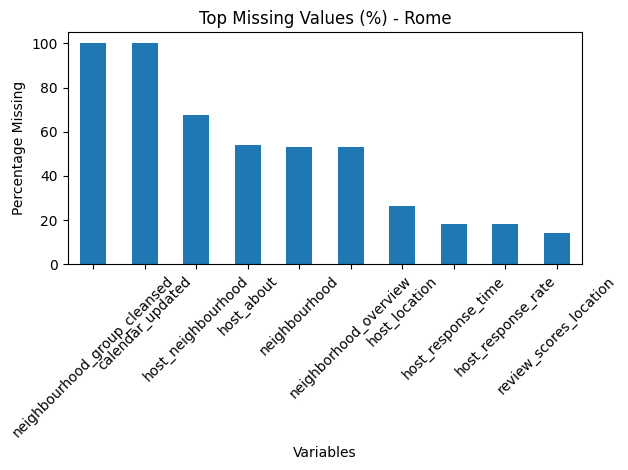

In [15]:
top_missing = missing_pct_rome.head(10)

plt.figure()
top_missing.plot(kind='bar')
plt.title("Top Missing Values (%) - Rome")
plt.xlabel("Variables")
plt.ylabel("Percentage Missing")
plt.xticks(rotation=45)
plt.tight_layout()


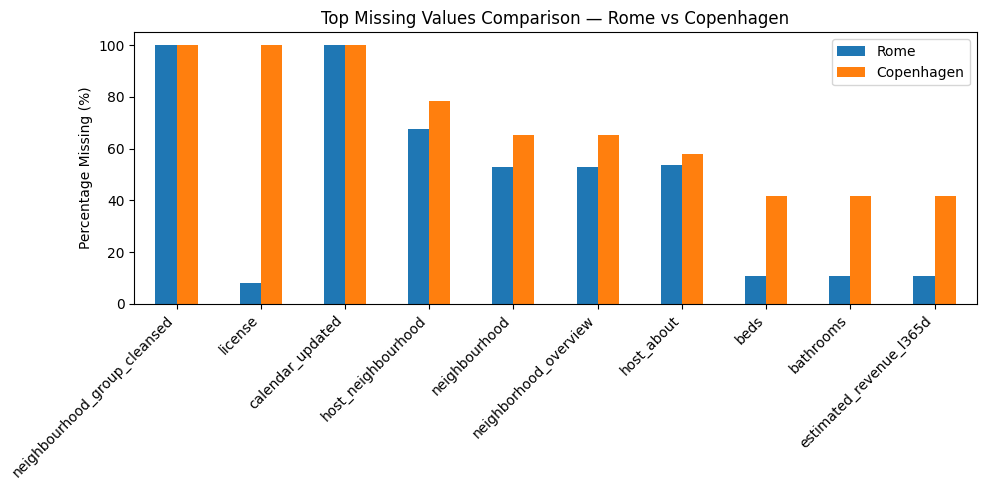

In [16]:
compare_missing = pd.DataFrame({
    "Rome": missing_pct_rome,
    "Copenhagen": missing_pct_cop
}).fillna(0)


top_compare = compare_missing.loc[
    compare_missing.max(axis=1).sort_values(ascending=False).head(10).index
]

top_compare.plot(kind='bar', figsize=(10, 5))
plt.title("Top Missing Values Comparison — Rome vs Copenhagen")
plt.ylabel("Percentage Missing (%)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()


### Selection of Relevant Variables

To align the dataset with the research objectives, a subset of key variables is selected. These variables capture host activity, pricing, availability, and spatial characteristics.

The selected variables include:

- host identifiers (host_id)  

- number of listings per host (calculated_host_listings_count)  

- room type (room_type)  

- price (price)  

- availability (availability_365)  

- demand proxies (number_of_reviews, reviews_per_month)  

- estimated revenue  

- neighbourhood and geographic coordinates  

This reduction simplifies the dataset while preserving all relevant information needed for the analysis.

In [17]:
key_vars = [
    "host_id",
    "calculated_host_listings_count",
    "room_type",
    "price",
    "minimum_nights",
    "availability_365",
    "number_of_reviews",
    "reviews_per_month",
    "estimated_revenue_l365d",
    "neighbourhood_cleansed",
    "latitude",
    "longitude"
]

df_rome = df_rome[key_vars].copy()
df_cop = df_cop[key_vars].copy()


### Distribution Analysis
Before applying transformations, the distributions of key variables are analyzed to identify structural patterns and potential anomalies.

The distribution of listings per host is highly right-skewed in both cities, with most hosts managing a single listing and a small number controlling multiple properties. This long-tail pattern suggests potential market concentration.

Price distributions also exhibit strong right skewness, with a concentration of observations at lower price levels and a long upper tail. This indicates the presence of extreme values that may distort statistical analysis.

Availability patterns differ across cities: Rome shows a higher concentration of listings available throughout the year, while Copenhagen exhibits a more dispersed distribution. This suggests different usage patterns of listings across the two markets.

These distributional properties justify the use of logarithmic scales for visualization and motivate the adoption of a percentile-based approach for outlier removal in subsequent steps.

In [ ]:
df_rome.head()

In [ ]:
df_cop.head()

Text(0, 0.5, 'Frequency')

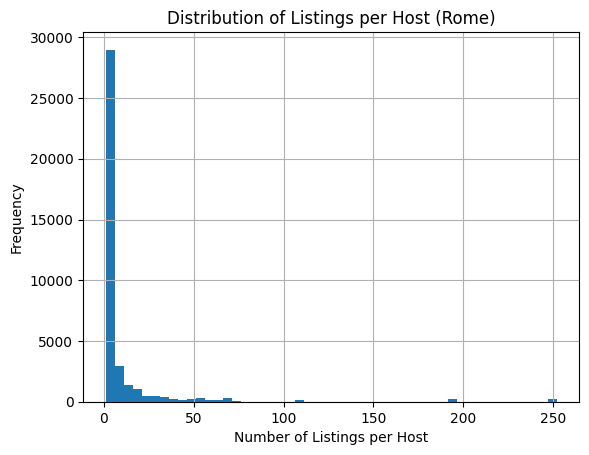

In [20]:
plt.figure()

df_rome["calculated_host_listings_count"].hist(bins=50)

plt.title("Distribution of Listings per Host (Rome)")
plt.xlabel("Number of Listings per Host")
plt.ylabel("Frequency")

Text(0, 0.5, 'Frequency (log scale)')

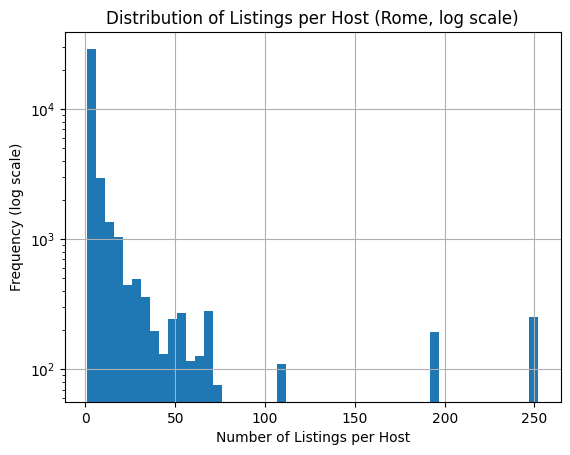

In [21]:
plt.figure()

df_rome["calculated_host_listings_count"].hist(bins=50)

plt.yscale("log")

plt.title("Distribution of Listings per Host (Rome, log scale)")
plt.xlabel("Number of Listings per Host")
plt.ylabel("Frequency (log scale)")

Text(0, 0.5, 'Frequency')

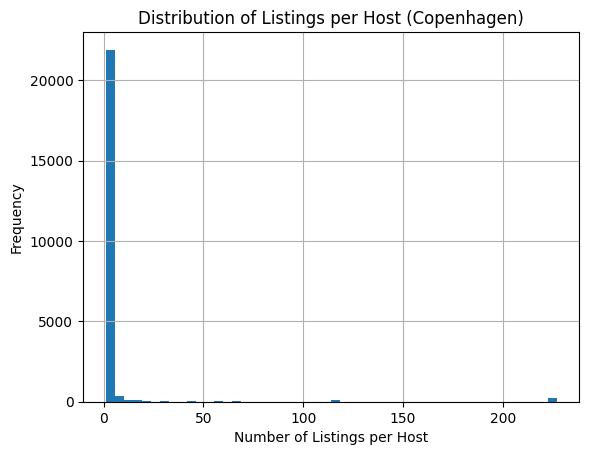

In [22]:
plt.figure()

df_cop["calculated_host_listings_count"].hist(bins=50)

plt.title("Distribution of Listings per Host (Copenhagen)")
plt.xlabel("Number of Listings per Host")
plt.ylabel("Frequency")

Text(0, 0.5, 'Frequency (log scale)')

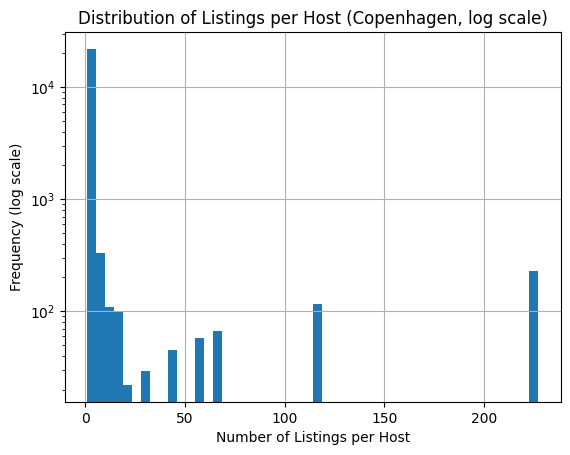

In [23]:
plt.figure()

df_cop["calculated_host_listings_count"].hist(bins=50)

plt.yscale("log")

plt.title("Distribution of Listings per Host (Copenhagen, log scale)")
plt.xlabel("Number of Listings per Host")
plt.ylabel("Frequency (log scale)")

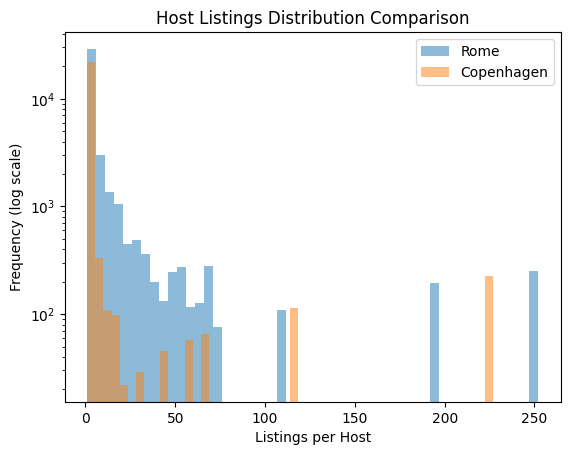

In [24]:
plt.figure()

plt.hist(df_rome["calculated_host_listings_count"], bins=50, alpha=0.5, label="Rome")
plt.hist(df_cop["calculated_host_listings_count"], bins=50, alpha=0.5, label="Copenhagen")

plt.yscale("log")

plt.title("Host Listings Distribution Comparison")
plt.xlabel("Listings per Host")
plt.ylabel("Frequency (log scale)")
plt.legend()


### Price Transformation and Currency Conversion

The price variable is originally stored as a string including currency symbols. It is converted into a numeric format to enable quantitative analysis.

Since the Copenhagen dataset reports prices in Danish Krone (DKK), all values are converted into euros (EUR) using a fixed exchange rate (1 DKK = 0.134 EUR). This ensures comparability between the two cities.

Using a fixed exchange rate ensures internal consistency of the dataset, although it does not account for short-term currency fluctuations.

In [25]:
for df in [df_rome, df_cop]:
    df["price"] = (
        df["price"]
        .replace(r"[\$,]", "", regex=True)
        .astype(float)
    )

In [26]:
DKK_TO_EUR = 0.134
df_cop["price"] = df_cop["price"] * DKK_TO_EUR

print("Copenhagen price after conversion:")
print(df_cop["price"].describe().round(2))

Copenhagen price after conversion:
count    13442.00
mean       193.76
std        261.90
min         18.22
25%        120.60
50%        160.80
75%        222.84
max      15135.97
Name: price, dtype: float64


In [27]:
print(df_rome["price"].describe())
print(df_cop["price"].describe())

count    33564.000000
mean       197.328000
std        443.190521
min          8.000000
25%         93.000000
50%        133.000000
75%        195.250000
max      10515.000000
Name: price, dtype: float64
count    13442.000000
mean       193.758118
std        261.899531
min         18.224000
25%        120.600000
50%        160.800000
75%        222.842000
max      15135.970000
Name: price, dtype: float64


Text(0, 0.5, 'Frequency')

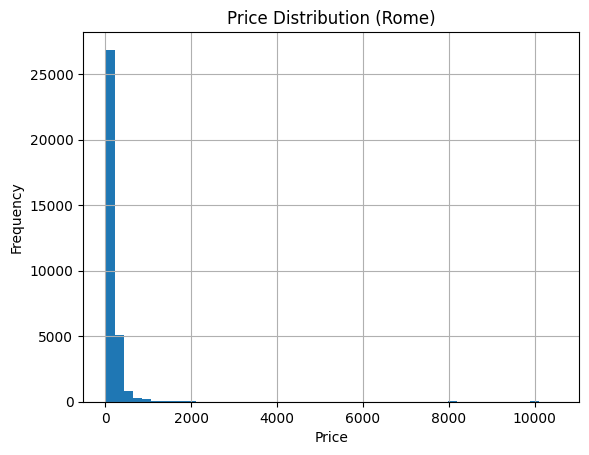

In [28]:
plt.figure()
df_rome["price"].hist(bins=50)

plt.title("Price Distribution (Rome)")
plt.xlabel("Price")
plt.ylabel("Frequency")


Text(0, 0.5, 'Frequency (log scale)')

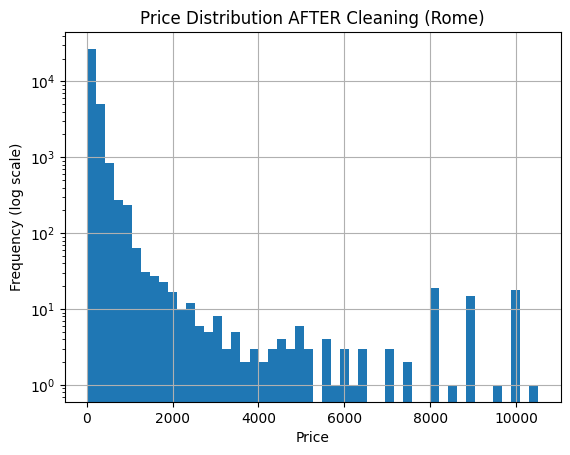

In [29]:
plt.figure()
df_rome["price"].hist(bins=50)

plt.yscale("log")

plt.title("Price Distribution AFTER Cleaning (Rome)")
plt.xlabel("Price")
plt.ylabel("Frequency (log scale)")

Text(0, 0.5, 'Frequency')

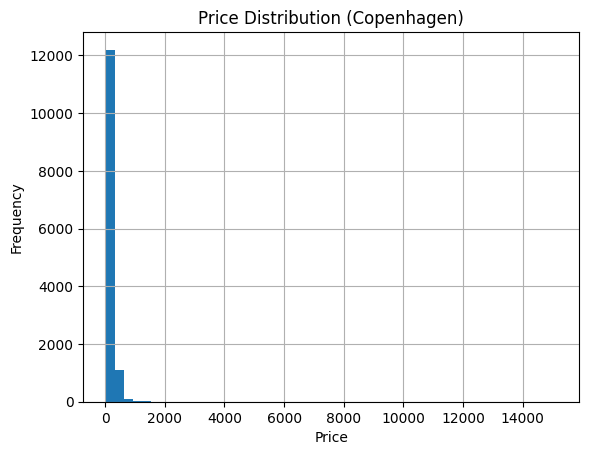

In [30]:
plt.figure()
df_cop["price"].hist(bins=50)

plt.title("Price Distribution (Copenhagen)")
plt.xlabel("Price")
plt.ylabel("Frequency")

Text(0, 0.5, 'Frequency (log scale)')

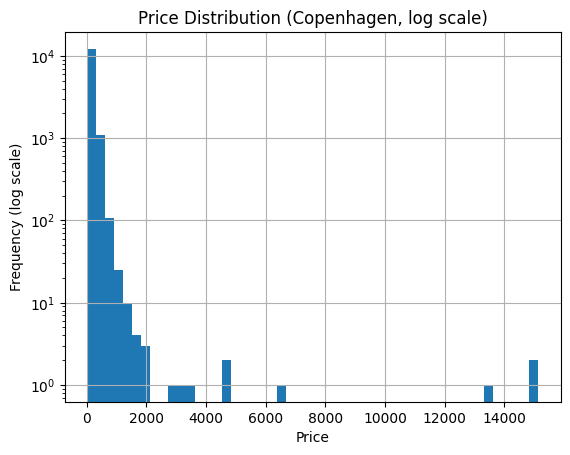

In [31]:
plt.figure()
df_cop["price"].hist(bins=50)

plt.yscale("log")

plt.title("Price Distribution (Copenhagen, log scale)")
plt.xlabel("Price")
plt.ylabel("Frequency (log scale)")

Text(0, 0.5, 'Frequency')

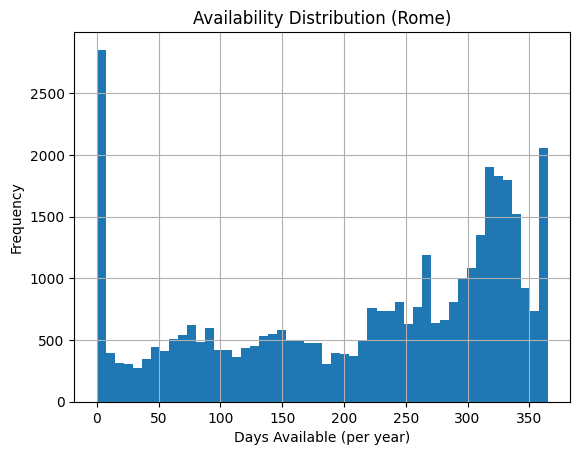

In [32]:
plt.figure()
df_rome["availability_365"].hist(bins=50)

plt.title("Availability Distribution (Rome)")
plt.xlabel("Days Available (per year)")
plt.ylabel("Frequency")

Text(0, 0.5, 'Frequency')

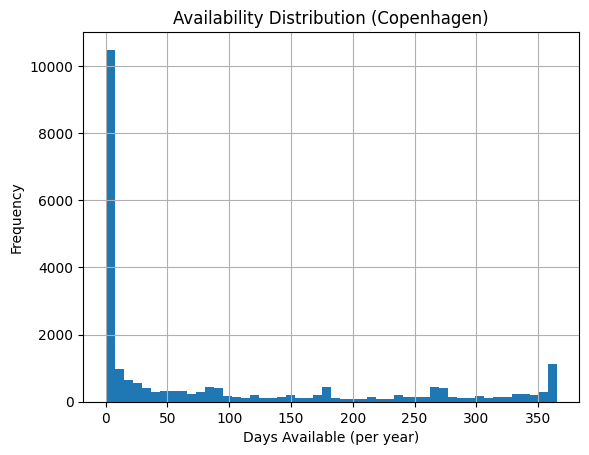

In [33]:
plt.figure()
df_cop["availability_365"].hist(bins=50)

plt.title("Availability Distribution (Copenhagen)")
plt.xlabel("Days Available (per year)")
plt.ylabel("Frequency")

In [34]:
print("Rome neighbourhoods:", df_rome["neighbourhood_cleansed"].nunique())
print("Copenhagen neighbourhoods:", df_cop["neighbourhood_cleansed"].nunique())

Rome neighbourhoods: 15
Copenhagen neighbourhoods: 11


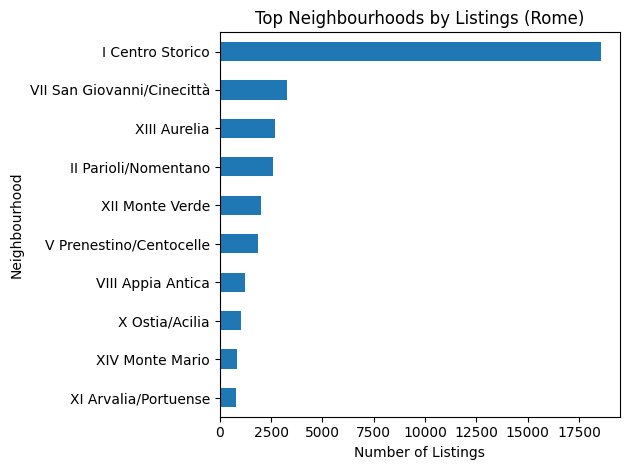

In [35]:
top_neigh = df_rome["neighbourhood_cleansed"].value_counts().head(10)

plt.figure()

top_neigh.sort_values().plot(kind="barh")

plt.title("Top Neighbourhoods by Listings (Rome)")
plt.xlabel("Number of Listings")
plt.ylabel("Neighbourhood")

plt.tight_layout()


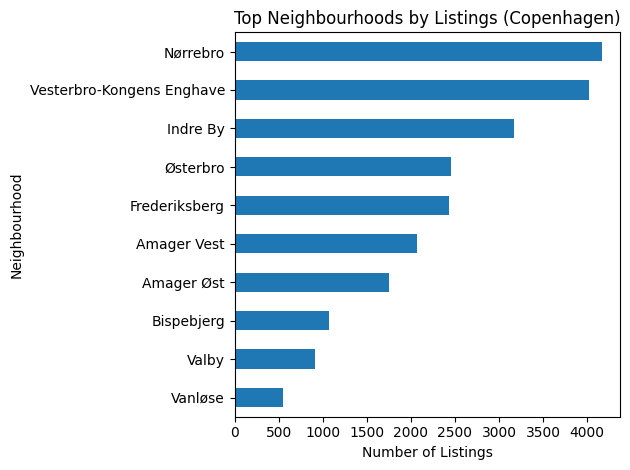

In [36]:
top_neigh = df_cop["neighbourhood_cleansed"].value_counts().head(10)

plt.figure()

top_neigh.sort_values().plot(kind="barh")

plt.title("Top Neighbourhoods by Listings (Copenhagen)")
plt.xlabel("Number of Listings")
plt.ylabel("Neighbourhood")

plt.tight_layout()

### Handling Missing Values in Key Variables
After restricting the dataset to relevant variables, missingness is significantly reduced and concentrated in a few key fields.
In particular, the price variable exhibits substantial missingness in Copenhagen (approximately 41%), compared to a lower proportion in Rome (approximately 11%).
Given the central role of price in the analysis, observations with missing price values are removed. While this reduces the sample size—especially for Copenhagen—it avoids introducing bias from unreliable imputations.
Missing values in reviews_per_month are retained, as they likely reflect new or inactive listings rather than data quality issues.
The variable estimated_revenue_l365d is also retained, but interpreted with caution, as it is derived rather than directly observed.

The removal of observations with missing price values results in a substantial reduction of the Copenhagen dataset (approximately 41% of observations). This introduces a potential selection bias, as the remaining sample may not be fully representative of the original market.
However, given the central role of price in the analysis and the lack of reliable imputation strategies, this trade-off is considered acceptable to preserve analytical validity.

In [37]:
df_rome.isnull().sum()


host_id                              0
calculated_host_listings_count       0
room_type                            0
price                             4088
minimum_nights                       0
availability_365                     0
number_of_reviews                    0
reviews_per_month                 5397
estimated_revenue_l365d           4088
neighbourhood_cleansed               0
latitude                             0
longitude                            0
dtype: int64

In [38]:
df_cop.isnull().sum()

host_id                              0
calculated_host_listings_count       0
room_type                            0
price                             9552
minimum_nights                       0
availability_365                     0
number_of_reviews                    0
reviews_per_month                 2371
estimated_revenue_l365d           9552
neighbourhood_cleansed               0
latitude                             0
longitude                            0
dtype: int64

In [39]:
missing_pct_cop.head(15)

license                         100.000000
calendar_updated                100.000000
neighbourhood_group_cleansed    100.000000
host_neighbourhood               78.546577
neighborhood_overview            65.273550
neighbourhood                    65.273550
host_about                       58.067322
beds                             41.558667
bathrooms                        41.554319
price                            41.541272
estimated_revenue_l365d          41.541272
host_response_rate               36.392102
host_response_time               36.392102
host_acceptance_rate             22.697225
host_location                    16.495608
dtype: float64

In [40]:
df_rome = df_rome.dropna(subset=["price"])
df_cop = df_cop.dropna(subset=["price"])

### Outlier Detection and Treatment
A percentile-based approach is preferred over the interquartile range (IQR) method because the price distribution is strongly right-skewed. The IQR method would incorrectly classify legitimate high-end listings as outliers, whereas the 99th percentile threshold removes only extreme anomalies while preserving the meaningful upper tail of the distribution.

Text(0.5, 0, 'Price')

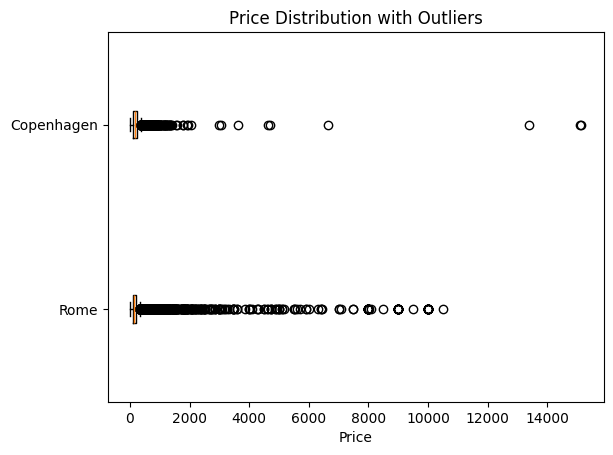

In [41]:
plt.figure()

plt.boxplot(
    [df_rome["price"], df_cop["price"]],
    tick_labels=["Rome", "Copenhagen"],
    vert=False
)

plt.title("Price Distribution with Outliers")
plt.xlabel("Price")

Text(0.5, 0, 'Price (log scale)')

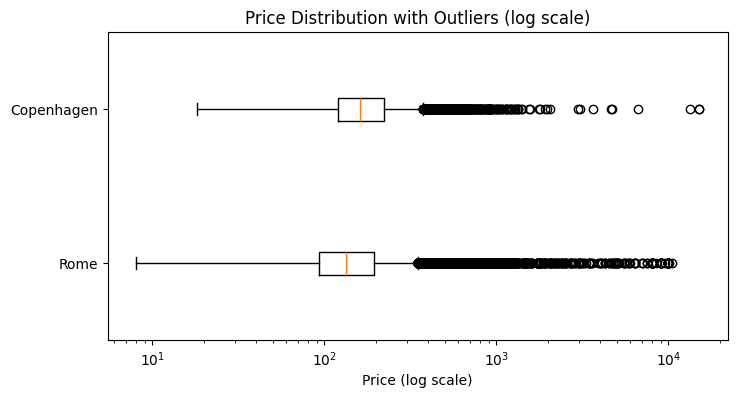

In [42]:
plt.figure(figsize=(8,4))

plt.boxplot(
    [df_rome["price"], df_cop["price"]],
    tick_labels=["Rome", "Copenhagen"],
    vert=False
)

plt.xscale("log")
plt.title("Price Distribution with Outliers (log scale)")
plt.xlabel("Price (log scale)")


### Removing extreme outliers

We use the 99th percentile rather than the IQR method because Airbnb  prices are strongly right-skewed by nature. IQR is designed for approximately normal distributions and would remove legitimate high-end listings (villas, penthouses) that are real market participants.

In [43]:
p99_rome = df_rome["price"].quantile(0.99)
p99_cop  = df_cop["price"].quantile(0.99)

print(f"Rome 99th percentile:       €{p99_rome:.2f}")
print(f"Copenhagen 99th percentile: €{p99_cop:.2f}")


rome_before = len(df_rome)
cop_before  = len(df_cop)


df_rome = df_rome[df_rome["price"] <= p99_rome]
df_cop  = df_cop[df_cop["price"]  <= p99_cop]


print(f"\nRome:       {rome_before} → {len(df_rome)} rows ({rome_before - len(df_rome)} dropped)")
print(f"Copenhagen: {cop_before} → {len(df_cop)} rows ({cop_before - len(df_cop)} dropped)")

Rome 99th percentile:       €1005.74
Copenhagen 99th percentile: €658.12

Rome:       33564 → 33228 rows (336 dropped)
Copenhagen: 13442 → 13307 rows (135 dropped)


In [44]:
print("\nAfter cleaning:")
print(df_rome["price"].describe().round(2))
print(df_cop["price"].describe().round(2))


After cleaning:
count    33228.00
mean       165.78
std        123.87
min          8.00
25%         93.00
50%        132.00
75%        192.00
max       1005.00
Name: price, dtype: float64
count    13307.00
mean       181.80
std         92.26
min         18.22
25%        120.60
50%        160.80
75%        219.42
max        656.06
Name: price, dtype: float64


### Final Standardization
To ensure consistency across datasets:
- column names are standardized (lowercase, underscore format)  
- neighbourhood variables are harmonized  
- a city identifier is added  
This step ensures full structural alignment between the two datasets, enabling seamless integration and consistent cross-city comparison in subsequent analyses.

In [45]:
def clean_columns(df): 
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )
    return df

In [46]:
df_rome = clean_columns(df_rome)
df_cop = clean_columns(df_cop)

In [47]:
df_rome["city"] = "Rome"
df_cop["city"] = "Copenhagen"

In [48]:
df_rome.rename(columns={
    "neighbourhood_cleansed": "neighbourhood"
}, inplace=True)

df_cop.rename(columns={
    "neighbourhood_cleansed": "neighbourhood"
}, inplace=True)

Text(0.5, 1.0, 'Price Distribution After Cleaning (Rome)')

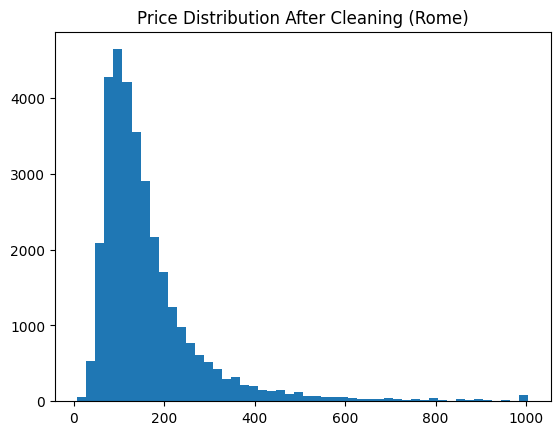

In [49]:
plt.figure()
plt.hist(df_rome["price"], bins=50)
plt.title("Price Distribution After Cleaning (Rome)")


Text(0.5, 1.0, 'Price Distribution After Cleaning (Copenhagen)')

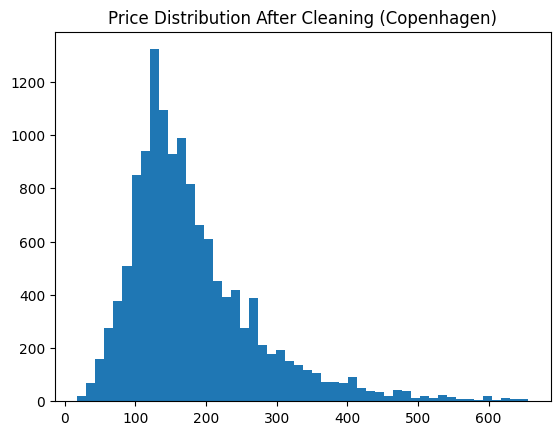

In [50]:
plt.figure()
plt.hist(df_cop["price"], bins=50)
plt.title("Price Distribution After Cleaning (Copenhagen)")


### Final Outcome
The cleaning process results in two consistent and comparable datasets characterized by:
- a reduced and relevant set of variables  
- controlled missingness in key fields  
- standardized pricing in a common currency  
- reduced influence of extreme values  
Overall, the cleaning strategy prioritizes comparability and analytical robustness over data completeness.

# DATA INTEGRATION

Before merging the datasets, we verify that Rome and Copenhagen have identical structures to ensure compatibility. The two datasets share the same variables, allowing a direct merge.

In [51]:
print("ROME:")
print(df_rome.columns)

print("\nCOPENHAGEN:")
print(df_cop.columns)

ROME:
Index(['host_id', 'calculated_host_listings_count', 'room_type', 'price',
       'minimum_nights', 'availability_365', 'number_of_reviews',
       'reviews_per_month', 'estimated_revenue_l365d', 'neighbourhood',
       'latitude', 'longitude', 'city'],
      dtype='str')

COPENHAGEN:
Index(['host_id', 'calculated_host_listings_count', 'room_type', 'price',
       'minimum_nights', 'availability_365', 'number_of_reviews',
       'reviews_per_month', 'estimated_revenue_l365d', 'neighbourhood',
       'latitude', 'longitude', 'city'],
      dtype='str')


### Merging the two datasets
The datasets are combined using vertical concatenation. Listings with missing room type are removed to ensure data consistency.

In [52]:
df = pd.concat([df_rome, df_cop], ignore_index=True)


In [53]:
df = df[df["room_type"].notna()]
print(f"After room_type filter: {len(df):,} rows")

After room_type filter: 46,535 rows


In [54]:
df.groupby("city")["price"].describe()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Copenhagen,13307.0,181.801789,92.257059,18.224,120.6,160.8,219.425,656.064
Rome,33228.0,165.777597,123.873342,8.000,93.0,132.0,192.000,1005.000


Prices differ across cities: Copenhagen shows higher average prices, while Rome exhibits greater variability and more extreme values.

In [55]:
print(f"Rome:        {len(df_rome):,} rows")
print(f"Copenhagen:  {len(df_cop):,} rows")
print(f"Combined:    {len(df):,} rows")

assert len(df) == len(df_rome) + len(df_cop)

print(f"\nShape: {df.shape}")
print(f"Cities: {df['city'].value_counts().to_dict()}")


Rome:        33,228 rows
Copenhagen:  13,307 rows
Combined:    46,535 rows

Shape: (46535, 13)
Cities: {'Rome': 33228, 'Copenhagen': 13307}


The final dataset contains 46,535 listings and is unbalanced, with Rome representing the majority of observations.
Each observation corresponds to a listing-level unit. This ensures that the analysis is conducted at the listing level rather than the host level.

In [56]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
host_id                              0
calculated_host_listings_count       0
room_type                            0
price                                0
minimum_nights                       0
availability_365                     0
number_of_reviews                    0
reviews_per_month                 5678
estimated_revenue_l365d              0
neighbourhood                        0
latitude                             0
longitude                            0
city                                 0
dtype: int64


Missing values are minimal and concentrated in reviews_per_month, which is retained as it reflects listing activity (e.g., new or inactive listings).

# FEATURE ENGINEERING


The locally computed variable host_listings_local is used instead of the original calculated_host_listings_count.


We derive the analytical variables needed for the host 
concentration analysis and the Urban Pressure Index.

Three sets of features are created:
- **Host-level**: listings per host (local count) and 
  host category classification
- **Neighbourhood-level**: aggregated metrics per area
- **Urban Pressure Index**: composite metric combining 
  listing intensity and availability

### Listing per Host

In [57]:
host_counts = (
    df.groupby(["city", "host_id"])
    .size()
    .rename("host_listings_local")
    .reset_index()
)


df = df.merge(host_counts, on=["city", "host_id"], how="left")


df["count_diff"] = df["calculated_host_listings_count"] - df["host_listings_local"]
print("Difference between calculated and local count:")
print(df["count_diff"].describe().round(2))
print(f"\nListings where counts differ: {(df['count_diff'] != 0).sum():,}")
print(f"Total listings: {len(df):,}")


df = df.drop(columns=["count_diff"])


Difference between calculated and local count:
count    46535.00
mean         0.64
std          2.71
min          0.00
25%          0.00
50%          0.00
75%          0.00
max         31.00
Name: count_diff, dtype: float64

Listings where counts differ: 7,381
Total listings: 46,535


### Host classification

We classify hosts into three categories based on the number of 
listings they manage within each city:

| Category | Listings | Interpretation |
|---|---|---|
| Casual | 1 | Occasional host, sharing economy model |
| Semi-professional | 2–4 | Small multi-listing operator |
| Professional | 5+ | Commercial operator |

This classification serves as a proxy for the degree of market professionalisation, allowing us to distinguish between occasional participation and commercial-scale activity within the short-term rental market.

In [58]:
def classify_host(n):
    if n == 1:
        return "Casual"
    elif n <= 4:
        return "Semi-professional"
    else:
        return "Professional"

df["host_category"] = df["host_listings_local"].apply(classify_host)


print(df.groupby(["city", "host_category"]).size())

city        host_category    
Copenhagen  Casual               11350
            Professional          1042
            Semi-professional      915
Rome        Casual               13810
            Professional          9766
            Semi-professional     9652
dtype: int64


In [59]:
# --- ROOM TYPE BY HOST CATEGORY ---

room_host = (
    df.groupby(["city", "host_category", "room_type"])
    .size()
    .reset_index(name="count")
)

room_host["share"] = (
    room_host.groupby(["city", "host_category"])["count"]
    .transform(lambda x: x / x.sum() * 100)
    .round(1)
)

room_host

,city,host_category,room_type,count,share
0,Copenhagen,Casual,Entire home/apt,10698,94.3
1,Copenhagen,Casual,Private room,650,5.7
2,Copenhagen,Casual,Shared room,2,0.0
3,Copenhagen,Professional,Entire home/apt,914,87.7
4,Copenhagen,Professional,Private room,116,11.1
5,Copenhagen,Professional,Shared room,12,1.2
6,Copenhagen,Semi-professional,Entire home/apt,556,60.8
7,Copenhagen,Semi-professional,Hotel room,3,0.3
8,Copenhagen,Semi-professional,Private room,353,38.6
9,Copenhagen,Semi-professional,Shared room,3,0.3


This breakdown highlights structural differences in how different types of hosts operate. In particular, professional hosts show a higher reliance on entire home listings, especially in Rome, indicating a stronger orientation towards commercial short-term rental activity.

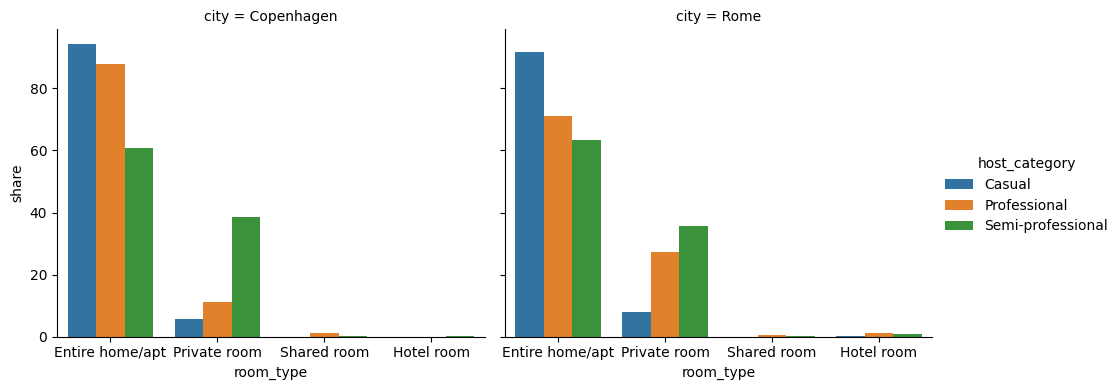

In [60]:
sns.catplot(
    data=room_host,
    x="room_type",
    y="share",
    hue="host_category",
    col="city",
    kind="bar",
    height=4,
    aspect=1.2
)

### Neighbourhood-Level Aggregates

We aggregate listing-level data at the neighbourhood level to capture the spatial distribution and intensity of Airbnb activity.

These aggregates provide proxies for local market pressure, including listing concentration, availability, and the presence of professional operators.

In [61]:
neighbourhood_stats = (
    df.groupby(["city", "neighbourhood"])
    .agg(
        listing_count       = ("host_id", "size"),
        avg_price           = ("price", "mean"),
        avg_availability    = ("availability_365", "mean"),
        professional_share  = (
            "host_category",
            lambda x: (x == "Professional").mean()
        )
    )
    .reset_index()
)

neighbourhood_stats["professional_share"] *= 100


print(neighbourhood_stats.shape)
neighbourhood_stats.head()

(26, 6)


,city,neighbourhood,listing_count,avg_price,avg_availability,professional_share
0,Copenhagen,Amager Vest,1225,182.267675,146.664490,8.000000
1,Copenhagen,Amager Øst,1020,167.886498,143.486275,8.137255
2,Copenhagen,Bispebjerg,595,135.060289,158.695798,8.739496
3,Copenhagen,Brønshøj-Husum,232,144.650690,177.521552,3.879310
4,Copenhagen,Frederiksberg,1402,183.692208,150.256776,4.065621


The share of professional hosts captures the extent to which Airbnb activity in each neighbourhood is driven by commercial operators rather than occasional hosts, providing an additional dimension of market structure.

## UPI


### Urban Pressure Index — Normalisation

Before combining the components, we normalise each variable to a 0–1 scale using min-max normalisation. Crucially, we normalise *within each city separately* — not globally.

This means a score of 1.0 represents the most pressured neighbourhood *in that city*, not across both cities. 
This is appropriate for our comparative question: we want to understand the internal distribution of pressure in each city, not rank absolute values across different urban contexts.

Listing count is interpreted as a proxy for listing intensity (rather than true density), as information on neighbourhood area is not available.

### Normalisation

In [62]:
scaler_main = MinMaxScaler()
scaler_price = MinMaxScaler()

for city in ["Rome", "Copenhagen"]:
    mask = neighbourhood_stats["city"] == city

    neighbourhood_stats.loc[mask, "listing_count_norm"] = scaler_main.fit_transform(
        neighbourhood_stats.loc[mask, ["listing_count"]]
    )
    
    neighbourhood_stats.loc[mask, "availability_norm"] = scaler_main.fit_transform(
        neighbourhood_stats.loc[mask, ["avg_availability"]]
    )

neighbourhood_stats[
    ["city", "neighbourhood", "listing_count_norm", "availability_norm"]
].head(10)

,city,neighbourhood,listing_count_norm,availability_norm
0,Copenhagen,Amager Vest,0.483447,0.241067
1,Copenhagen,Amager Øst,0.383642,0.162899
2,Copenhagen,Bispebjerg,0.176728,0.536979
3,Copenhagen,Brønshøj-Husum,0.000000,1.000000
4,Copenhagen,Frederiksberg,0.569620,0.329420
5,Copenhagen,Indre By,0.896787,0.971803
6,Copenhagen,Nørrebro,0.967868,0.000000
7,Copenhagen,Valby,0.118306,0.364942
8,Copenhagen,Vanløse,0.048199,0.464582
9,Copenhagen,Vesterbro-Kongens Enghave,1.000000,0.175598


Availability is interpreted as a proxy for the degree of commercial use of listings. Higher availability suggests that a property is actively rented on a short-term basis rather than used occasionally.

The combination of listing intensity and availability therefore captures both the scale and intensity of short-term rental activity.

In [63]:
# Urban Pressure Index (UPI) ---

neighbourhood_stats["UPI"] = (
    0.5 * neighbourhood_stats["listing_count_norm"] +
    0.5 * neighbourhood_stats["availability_norm"]
).round(4)

print("UPI distribution by city:")
print(neighbourhood_stats.groupby("city")["UPI"].describe().round(3))

UPI distribution by city:
            count   mean    std    min    25%    50%    75%    max
city                                                              
Copenhagen   11.0  0.442  0.197  0.242  0.315  0.412  0.492  0.934
Rome         15.0  0.270  0.180  0.040  0.169  0.244  0.363  0.666


### Top Neighbourhoods by UPI

In [64]:
for city in ["Rome", "Copenhagen"]:
    print(f"\n--- {city} — top 5 neighbourhoods by UPI ---")
    
    top = (
        neighbourhood_stats[neighbourhood_stats["city"] == city]
        .sort_values("UPI", ascending=False)
        .head(5)
    )
    
    print(
        top[
            ["neighbourhood", "listing_count", "avg_availability", "UPI"]
        ].to_string(index=False)
    )


--- Rome — top 5 neighbourhoods by UPI ---
      neighbourhood  listing_count  avg_availability    UPI
   I Centro Storico          16310        230.071245 0.6661
 XV Cassia/Flaminia            524        249.143130 0.5066
VI Roma delle Torri            312        246.717949 0.4575
             IX Eur            383        243.080940 0.3961
    XIV Monte Mario            769        238.603381 0.3298

--- Copenhagen — top 5 neighbourhoods by UPI ---
            neighbourhood  listing_count  avg_availability    UPI
                 Indre By           2074        176.375121 0.9343
Vesterbro-Kongens Enghave           2286        144.002625 0.5878
           Brønshøj-Husum            232        177.521552 0.5000
                 Nørrebro           2220        136.863063 0.4839
            Frederiksberg           1402        150.256776 0.4495


The results show that central and high-demand neighbourhoods consistently exhibit the highest levels of urban pressure. This reflects a concentration of listings combined with high availability, suggesting intensive use of properties for short-term rental purposes.

### Alternative UPI including price (not used)

We also compute an alternative version of the UPI that includes average price as a third component. This version is not used in 
the final analysis because Copenhagen has approximately 41% of listings with missing price data — including price would introduce 
a systematic bias in the cross-city comparison.

We document this alternative to demonstrate that the exclusion of price was an explicit methodological choice, not an oversight.

This alternative specification is retained for robustness analysis but excluded from the main results to avoid bias and ensure comparability across cities.

In [65]:
# Alternative UPI including price (not used in final analysis) 

# This version is exploratory and not used due to missing price data in Copenhagen

for city in ["Rome", "Copenhagen"]:
    mask = neighbourhood_stats["city"] == city
    
    neighbourhood_stats.loc[mask, "price_norm"] = scaler_price.fit_transform(
        neighbourhood_stats.loc[mask, ["avg_price"]]
    )

neighbourhood_stats["UPI_alt"] = (
    (1/3) * neighbourhood_stats["listing_count_norm"] +
    (1/3) * neighbourhood_stats["availability_norm"] +
    (1/3) * neighbourhood_stats["price_norm"]
).round(4)

## EXPLORATORY ANALYSIS

This section provides a descriptive overview of the Airbnb markets in Rome and Copenhagen. The analysis focuses on prices, host concentration, listing availability, room types, and spatial concentration patterns.

### Price distribution

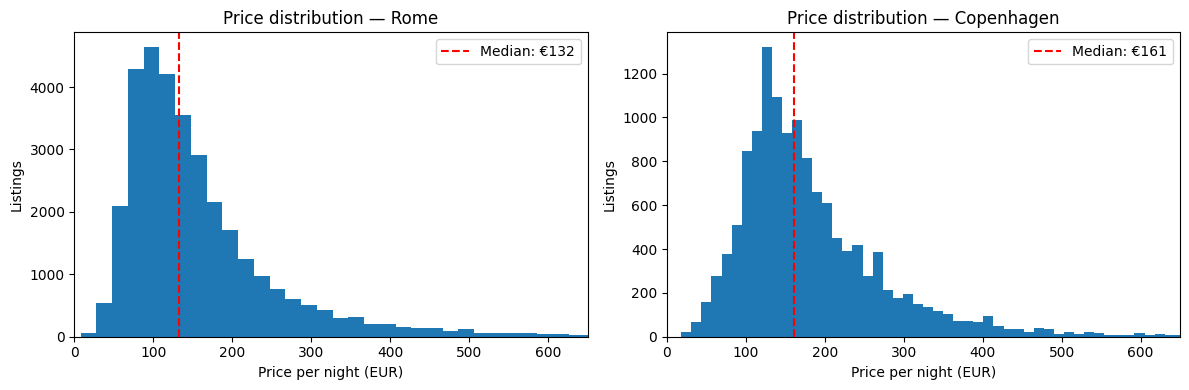

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

upper = df["price"].quantile(0.99)

for ax, city in zip(axes, ["Rome", "Copenhagen"]):
    subset = df[df["city"] == city]["price"]
    
    ax.hist(subset, bins=50, edgecolor="none")
    ax.set_xlim(0, upper)
    
    ax.set_title(f"Price distribution — {city}")
    ax.set_xlabel("Price per night (EUR)")
    ax.set_ylabel("Listings")
    
    ax.axvline(subset.median(), color="red", linestyle="--",
               label=f"Median: €{subset.median():.0f}")
    ax.legend()

plt.tight_layout()

Price distributions are right-skewed in both cities, with a limited number of high-price listings. Copenhagen shows higher median prices than Rome despite its lower level of host concentration.

### Host Concentration and Market Structure

Rome: 41.6% single-listing hosts, max 223 listings
Copenhagen: 85.3% single-listing hosts, max 223 listings


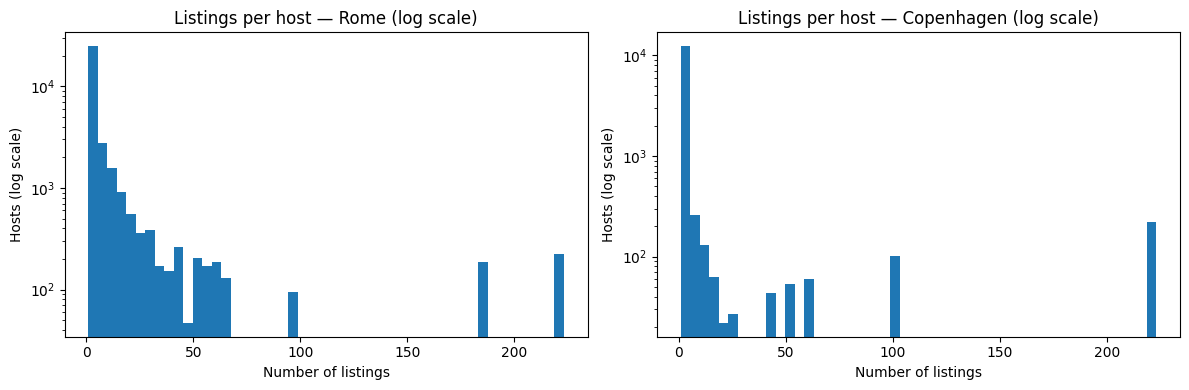

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, city in zip(axes, ["Rome", "Copenhagen"]):
    subset = df[df["city"] == city]["host_listings_local"]
    
    ax.hist(subset, bins=50)
    ax.set_yscale("log")
    
    ax.set_title(f"Listings per host — {city} (log scale)")
    ax.set_xlabel("Number of listings")
    ax.set_ylabel("Hosts (log scale)")

plt.tight_layout()


for city in ["Rome", "Copenhagen"]:
    s = df[df["city"] == city]["host_listings_local"]
    print(f"{city}: {(s == 1).mean()*100:.1f}% single-listing hosts, max {s.max()} listings")

The distribution of listings per host is highly concentrated in both cities. Copenhagen is dominated by single-listing hosts, while Rome shows a substantially larger presence of multi-listing operators.

Listing share by host category

In [68]:
listing_share = (
    df.groupby(["city", "host_category"])
    .size()
    .reset_index(name="listing_count")
)

listing_share["share"] = (
    listing_share.groupby("city")["listing_count"]
    .transform(lambda x: x / x.sum() * 100)
    .round(1)
)

print(listing_share.sort_values(["city", "host_category"]))

         city      host_category  listing_count  share
0  Copenhagen             Casual          11350   85.3
1  Copenhagen       Professional           1042    7.8
2  Copenhagen  Semi-professional            915    6.9
3        Rome             Casual          13810   41.6
4        Rome       Professional           9766   29.4
5        Rome  Semi-professional           9652   29.0


Host categories reveal important structural differences between the two cities. Rome exhibits a more commercialised market structure, while Copenhagen remains largely dominated by casual hosts.

### Availability Patterns

Rome: median 260 days, 67.9% available > 6 months
Copenhagen: median 115 days, 38.1% available > 6 months


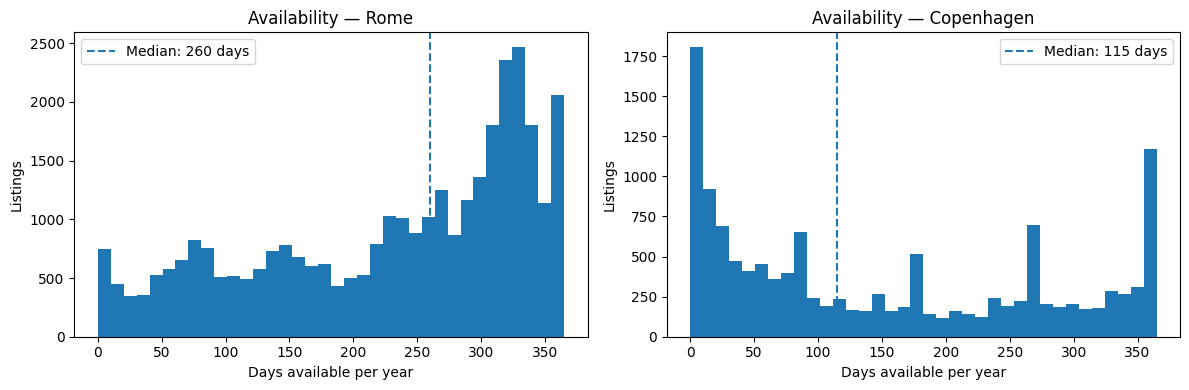

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, city in zip(axes, ["Rome", "Copenhagen"]):
    subset = df[df["city"] == city]["availability_365"]
    
    ax.hist(subset, bins=36)
    ax.set_title(f"Availability — {city}")
    ax.set_xlabel("Days available per year")
    ax.set_ylabel("Listings")
    
    ax.axvline(subset.median(), linestyle="--",
               label=f"Median: {subset.median():.0f} days")
    ax.legend()

plt.tight_layout()


for city in ["Rome", "Copenhagen"]:
    s = df[df["city"] == city]["availability_365"]
    print(f"{city}: median {s.median():.0f} days, {(s > 180).mean()*100:.1f}% available > 6 months")

Rome shows substantially higher listing availability than Copenhagen, suggesting a more persistent use of properties for short-term rentals throughout the year.

### Room Type Composition

In [70]:
room_share = (
    df.groupby(["city", "room_type"])
    .size()
    .reset_index(name="count")
)

room_share["share"] = (
    room_share.groupby("city")["count"]
    .transform(lambda x: x / x.sum() * 100)
    .round(1)
)

room_share

,city,room_type,count,share
0,Copenhagen,Entire home/apt,12168,91.4
1,Copenhagen,Hotel room,3,0.0
2,Copenhagen,Private room,1119,8.4
3,Copenhagen,Shared room,17,0.1
4,Rome,Entire home/apt,25739,77.5
5,Rome,Hotel room,204,0.6
6,Rome,Private room,7209,21.7
7,Rome,Shared room,76,0.2


/tmp/ipykernel_358/2494963157.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(subset["room_type"], rotation=30)
/tmp/ipykernel_358/2494963157.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(subset["room_type"], rotation=30)


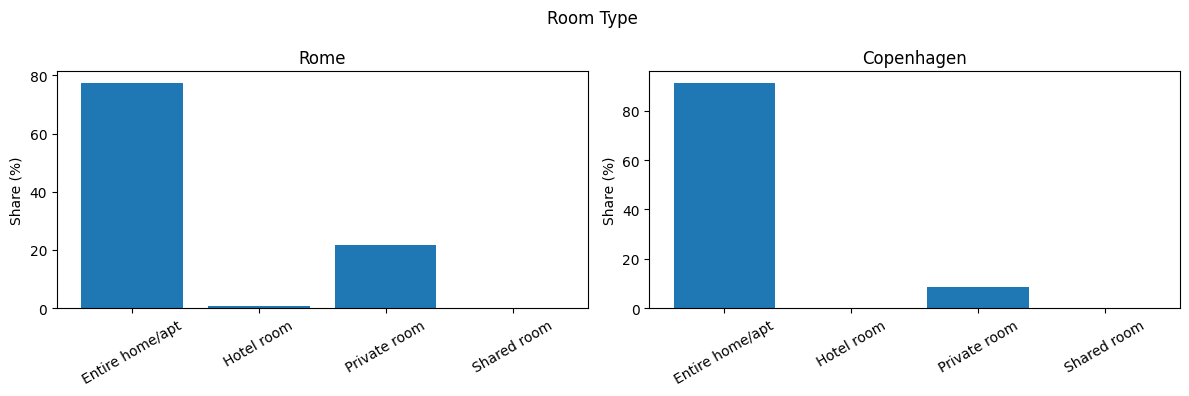

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

for ax, city in zip(axes, df["city"].unique()):
    subset = room_share[room_share["city"] == city]
    ax.bar(subset["room_type"], subset["share"])
    ax.set_title(f"{city}")
    ax.set_ylabel("Share (%)")
    ax.set_xticklabels(subset["room_type"], rotation=30)
    title = "Room Type "
    plt.suptitle(title)

plt.tight_layout()

Entire-home listings dominate in both cities, indicating that Airbnb activity primarily involves full residential units rather than shared accommodations.

In [72]:
df.groupby("city")["minimum_nights"].describe()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Copenhagen,13307.0,4.140828,12.105535,1.0,2.0,3.0,4.0,730.0
Rome,33228.0,4.254484,14.125233,1.0,1.0,2.0,3.0,730.0


Minimum-night requirements are generally low in both cities, indicating a strong orientation toward short-term urban stays.

### Key Insights from the Exploratory Analysis

Before moving to formal metrics, we summarise the main patterns emerging from the exploratory analysis. These observations help interpret the structural differences between Rome and Copenhagen and provide context for the subsequent analysis.

⸻

I1 — Rome shows a higher level of market concentration.
Rome has a much larger presence of professional and semi-professional hosts compared to Copenhagen. In Copenhagen, the majority of listings belong to single-listing hosts, suggesting a more decentralized and peer-to-peer market structure. In contrast, Rome shows a stronger commercial orientation, with a larger share of listings controlled by multi-listing operators.

⸻

I2 — Listing availability reveals different usage patterns.
Listings in Rome remain available for a significantly larger portion of the year, indicating a more intensive use of properties for short-term rental activity. Copenhagen shows lower median availability and fewer listings active for most of the year, suggesting a more occasional hosting model.

⸻

I3 — Prices are higher in Copenhagen despite lower concentration.
Median prices are higher in Copenhagen even though the market is less professionalized and less concentrated than Rome. This suggests that Airbnb prices are influenced not only by host concentration, but also by broader housing-market conditions and possible supply constraints.

⸻

I4 — Entire-home listings dominate in both cities.
In both Rome and Copenhagen, most Airbnb listings consist of entire homes rather than private or shared rooms. This indicates that short-term rental activity may directly reduce the availability of housing units for long-term residents, especially in areas with high tourism demand.

⸻

I5 — Spatial concentration is more intense in Rome.
Airbnb activity in Rome is strongly concentrated in central neighbourhoods such as Centro Storico, which show extremely high listing counts and strong professional-host presence. Copenhagen also exhibits spatial concentration, but at a lower scale and with less evidence of commercial clustering.

⸻

I6 — The two cities reflect different Airbnb market structures.
Overall, the results suggest that Rome operates as a more commercialized short-term rental market, while Copenhagen retains stronger characteristics of a peer-to-peer hosting system. These differences likely reflect broader urban, tourism, and housing-market dynamics.

⸻

I7 — Urban pressure emerges through different mechanisms.
The Urban Pressure Index highlights different sources of pressure across the two cities. In Rome, pressure is mainly associated with high listing concentration and professional activity. In Copenhagen, pressure is linked more to listing availability within specific neighbourhoods, despite a smaller overall market size.

## ANALYTICAL METRICS

This section applies formal concentration and inequality metrics to compare the Airbnb market structures of Rome and Copenhagen. Different metrics capture different dimensions of concentration: Lorenz curves and Gini coefficients measure inequality in listing distribution, dominance metrics capture market control by large operators, while HHI provides a standard economic concentration indicator.

In [73]:
for city in ["Rome", "Copenhagen"]:
    print(f"\n--- {city} — Neighbourhood UPI ranking ---")
    ranked = (
        neighbourhood_stats[neighbourhood_stats["city"] == city]
        .sort_values("UPI", ascending=False)
        [["neighbourhood", "listing_count", "avg_availability", 
          "professional_share", "UPI"]]
    )
    print(ranked.to_string(index=False))




--- Rome — Neighbourhood UPI ranking ---
             neighbourhood  listing_count  avg_availability  professional_share    UPI
          I Centro Storico          16310        230.071245           38.835071 0.6661
        XV Cassia/Flaminia            524        249.143130           24.045802 0.5066
       VI Roma delle Torri            312        246.717949           10.256410 0.4575
                    IX Eur            383        243.080940           13.838120 0.3961
           XIV Monte Mario            769        238.603381           23.146944 0.3298
         VIII Appia Antica           1079        237.047266           22.057461 0.3122
              XIII Aurelia           2435        231.429158           24.394251 0.2562
VII San Giovanni/Cinecittà           2944        229.847486           20.448370 0.2445
      II Parioli/Nomentano           2253        229.563249           27.607634 0.2179
      XI Arvalia/Portuense            634        231.214511           14.353312 0.1962
 

UPI values are highest in central and tourism-oriented neighbourhoods in both cities. Rome exhibits higher professional-host shares across several districts, while Copenhagen shows a more localized concentration around Indre By.

### Lorenz curve

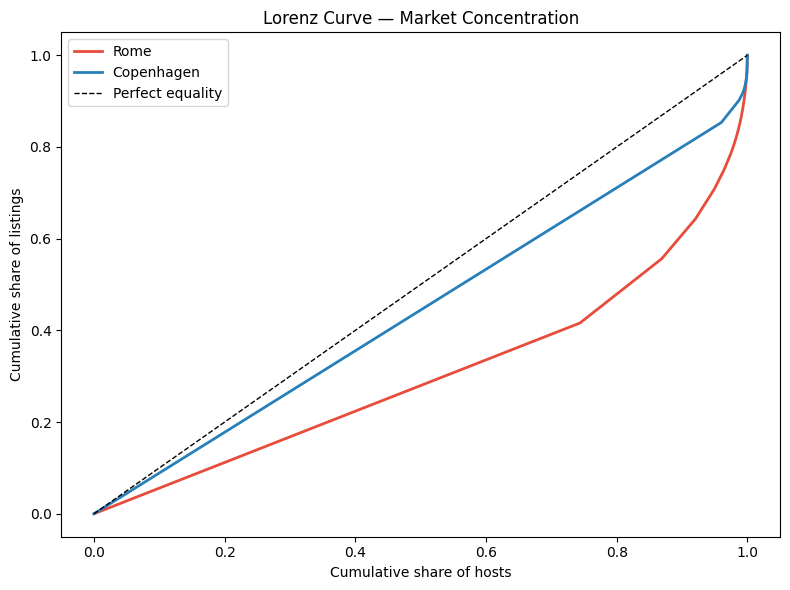

In [74]:
def lorenz_curve(values):
    sorted_vals = np.sort(values)
    cumulative = np.cumsum(sorted_vals)
    cumulative = cumulative / cumulative[-1]
    x = np.linspace(0, 1, len(cumulative))
    return x, cumulative

fig, ax = plt.subplots(figsize=(8, 6))

for city, color in [("Rome", "#e74c3c"), ("Copenhagen", "#2980b9")]:
    host_data = (
        df[df["city"] == city]
        .groupby("host_id")["host_listings_local"]
        .first()
        .values
    )
    x, y = lorenz_curve(host_data)
    ax.plot(x, y, label=city, color=color, linewidth=2)

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Perfect equality")

ax.set_xlabel("Cumulative share of hosts")
ax.set_ylabel("Cumulative share of listings")
ax.set_title("Lorenz Curve — Market Concentration")
ax.legend()

plt.tight_layout()

The Lorenz curves indicate a more unequal distribution of listings in Rome compared to Copenhagen. Listing ownership in Rome is more concentrated among a smaller group of hosts.

### Gini coefficient 

In [75]:
def gini(values):
    sorted_vals = np.sort(values)
    n = len(sorted_vals)
    cumulative = np.cumsum(sorted_vals)
    return (2 * np.sum((np.arange(1, n+1) * sorted_vals)) 
            / (n * cumulative[-1])) - (n + 1) / n

for city in ["Rome", "Copenhagen"]:
    host_data = (
        df[df["city"] == city]
        .groupby("host_id")["host_listings_local"]
        .first()
        .values
    )
    g = gini(host_data)
    print(f"{city} Gini coefficient: {g:.4f}")

Rome Gini coefficient: 0.3873
Copenhagen Gini coefficient: 0.1098


The Gini coefficient confirms stronger host concentration in Rome (0.387) than in Copenhagen (0.110), indicating a higher level of inequality in listing ownership.

### Top host dominance

In [76]:
for city in ["Rome", "Copenhagen"]:
    host_data = (
        df[df["city"] == city]
        .groupby("host_id")["host_listings_local"]
        .first()
        .sort_values(ascending=False)
    )
    
    total   = host_data.sum()
    top_1p  = host_data.iloc[:max(1, int(len(host_data) * 0.01))].sum()
    top_10p = host_data.iloc[:max(1, int(len(host_data) * 0.10))].sum()
    
    print(f"\n{city}")
    print(f"  Total hosts:          {len(host_data):,}")
    print(f"  Top 1% controls:      {top_1p/total*100:.1f}% of listings")
    print(f"  Top 10% controls:     {top_10p/total*100:.1f}% of listings")


Rome
  Total hosts:          18,576
  Top 1% controls:      13.9% of listings
  Top 10% controls:     39.2% of listings

Copenhagen
  Total hosts:          11,823
  Top 1% controls:      9.1% of listings
  Top 10% controls:     20.0% of listings


Top-host dominance is substantially stronger in Rome. The top 10% of hosts control almost 40% of listings, compared to 20% in Copenhagen.

### Share host per category 

In [77]:
summary = (
    df.groupby(["city", "host_category"])
    .agg(
        n_listings = ("host_id", "count"),
        n_hosts    = ("host_id", "nunique")
    )
    .reset_index()
)

for city in ["Rome", "Copenhagen"]:
    sub = summary[summary["city"] == city].copy()
    
    sub["listing_share"] = (sub["n_listings"] / sub["n_listings"].sum() * 100).round(1)
    sub["host_share"]    = (sub["n_hosts"]    / sub["n_hosts"].sum()    * 100).round(1)
    
    print(f"\n--- {city} ---")
    print(sub[["host_category", "n_hosts", "host_share", 
               "n_listings", "listing_share"]].to_string(index=False))


--- Rome ---
    host_category  n_hosts  host_share  n_listings  listing_share
           Casual    13810        74.3       13810           41.6
     Professional      952         5.1        9766           29.4
Semi-professional     3814        20.5        9652           29.0

--- Copenhagen ---
    host_category  n_hosts  host_share  n_listings  listing_share
           Casual    11350        96.0       11350           85.3
     Professional       70         0.6        1042            7.8
Semi-professional      403         3.4         915            6.9


Rome exhibits a more professionalized market structure, with professional and semi-professional hosts controlling a large share of listings. Copenhagen remains predominantly composed of casual hosts.

### HHI

In [78]:
hhi = (
    df.groupby(["city", "host_id"])["host_listings_local"]
    .first()
    .reset_index(name="listings")
)

hhi["share"] = (
    hhi.groupby("city")["listings"]
    .transform(lambda x: x / x.sum())
)

hhi["share_sq"] = hhi["share"] ** 2

hhi_result = hhi.groupby("city")["share_sq"].sum()

print("\nHHI (market concentration):")
for city in hhi_result.index:
    print(f"{city}: {hhi_result[city]:.4f}")


HHI (market concentration):
Copenhagen: 0.0005
Rome: 0.0003


HHI values are low in both cities because the market includes a very large number of hosts. For this reason, HHI is interpreted together with inequality and dominance metrics, which reveal substantially stronger concentration patterns in Rome.

### UPI link 

In [79]:
upi_link = (
    df.groupby(["city", "neighbourhood"])
    .agg(
        professional_share = ("host_category", lambda x: (x == "Professional").mean() * 100)
    )
    .reset_index()
)

upi_link = upi_link.merge(
    neighbourhood_stats[["city", "neighbourhood", "UPI"]],
    on=["city", "neighbourhood"],
    how="left"
)

print("\nUPI vs Professional Share:")
print(upi_link.head())


UPI vs Professional Share:
         city   neighbourhood  professional_share     UPI
0  Copenhagen     Amager Vest            8.000000  0.3623
1  Copenhagen      Amager Øst            8.137255  0.2733
2  Copenhagen      Bispebjerg            8.739496  0.3569
3  Copenhagen  Brønshøj-Husum            3.879310  0.5000
4  Copenhagen   Frederiksberg            4.065621  0.4495


Neighbourhoods with higher shares of professional hosts generally exhibit higher UPI values, particularly in central urban areas.

In [80]:
from scipy.stats import pearsonr
for city in ["Rome", "Copenhagen"]:
    sub = upi_link[upi_link["city"] == city].dropna()
    r, p = pearsonr(sub["professional_share"], sub["UPI"])
    print(f"{city}: r = {r:.3f}, p = {p:.3f}")


Rome: r = 0.548, p = 0.035
Copenhagen: r = 0.734, p = 0.010


The correlation analysis shows a positive relationship between professional-host share and UPI in both cities. In both cases, neighbourhoods with higher shares of professional hosts tend to exhibit higher urban pressure.

## EXPORTING THE DATASET

In [81]:
os.makedirs("data/export", exist_ok=True)

df.to_csv("data/export/listings_clean.csv", index=False)

host_stats = (
    df.groupby(["city", "host_id"])
    .agg(
        host_category    = ("host_category",      "first"),
        n_listings       = ("host_listings_local", "first"),
        avg_price        = ("price",               "mean"),
        avg_availability = ("availability_365",    "mean"),
        n_reviews        = ("number_of_reviews",   "sum")
    )
    .round(2)
    .reset_index()
)
host_stats.to_csv("data/export/host_stats.csv", index=False)

neighbourhood_stats.to_csv("data/export/neighbourhood_upi.csv", index=False)

print("Export complete.")
print(f"  listings_clean.csv    → {len(df)} rows")
print(f"  host_stats.csv        → {len(host_stats)} rows")
print(f"  neighbourhood_upi.csv → {len(neighbourhood_stats)} rows")

Export complete.
  listings_clean.csv    → 46535 rows
  host_stats.csv        → 30399 rows
  neighbourhood_upi.csv → 26 rows


In [82]:
OUTPUT     = "data/export/neighbourhoods_combined.geojson"


with open(PATH_GEO_RO, "r", encoding="utf-8") as f:
    rome = json.load(f)

with open(PATH_GEO_COP, "r", encoding="utf-8") as f:
    cop = json.load(f)

for feature in rome["features"]:
    feature["properties"]["city"] = "Rome"

for feature in cop["features"]:
    feature["properties"]["city"] = "Copenhagen"


combined = {
    "type": "FeatureCollection",
    "features": rome["features"] + cop["features"]
}


os.makedirs("data/export", exist_ok=True)
with open(OUTPUT, "w", encoding="utf-8") as f:
    json.dump(combined, f, ensure_ascii=False, indent=2)


print(f"Combined GeoJSON created: {OUTPUT}")
print(f"Total features: {len(combined['features'])}")
print(f"  Rome:       {len(rome['features'])}")
print(f"  Copenhagen: {len(cop['features'])}")


print("\nSample Rome feature properties:")
print(rome["features"][0]["properties"])
print("\nSample Copenhagen feature properties:")
print(cop["features"][0]["properties"])

Combined GeoJSON created: data/export/neighbourhoods_combined.geojson
Total features: 26
  Rome:       15
  Copenhagen: 11

Sample Rome feature properties:
{'neighbourhood': 'I Centro Storico', 'neighbourhood_group': None, 'city': 'Rome'}

Sample Copenhagen feature properties:
{'neighbourhood': 'Frederiksberg', 'neighbourhood_group': None, 'city': 'Copenhagen'}


# VISUALIZATIONS

### White-hat visualization

This scatter plot presents the relationship between professional host share and neighborhood-level Urban Pressure Index (UPI) for all 26 neighborhoods across both cities. The following design choices reflect white-hat principles:

- **Full data shown:** both Rome (n=15) and Copenhagen (n=11) are plotted together, allowing direct cross-city comparison and preventing cherry-picking of the stronger result;
- **Axes anchored at zero:** neither axis is truncated, so the visual slope of the regression line reflects the actual magnitude of the relationship — not an artificially inflated version of it;
- **Uncertainty is explicit:** 95% confidence intervals are shaded around each regression line. The reader can see how much the trend could plausibly vary;
- **Statistical evidence is stated:** Pearson r and p-values are annotated directly on the chart (Rome: r = 0.55, p = 0.035; Copenhagen: r = 0.73, p = 0.010), so the viewer can assess the strength of the correlation without taking it on faith;
- **Neutral color encoding:** city colors carry no emotional loading — they distinguish groups, nothing more;
- **Causation is explicitly disclaimed:** the caption reads *"Correlation does not imply causation"* and identifies UPI as an author-constructed composite, not an official statistic.

In [83]:
sns.set_theme(style='ticks', font_scale=0.95)
rome_color = '#4878CF'   
cph_color  = '#E8805A'   
dpi = 300

rome_r, rome_p = 0.548, 0.035
cph_r,  cph_p  = 0.734, 0.010

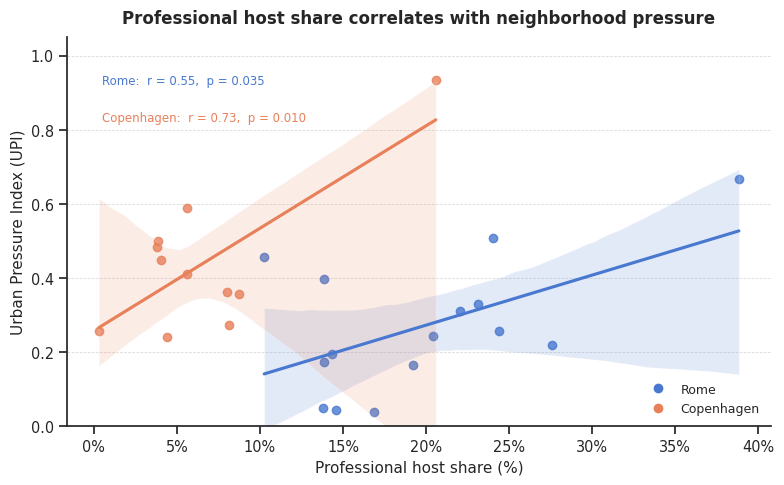

In [84]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.despine(ax=ax, top=True, right=True)

rome_data = neighbourhood_stats[neighbourhood_stats['city'] == 'Rome']
cph_data  = neighbourhood_stats[neighbourhood_stats['city'] == 'Copenhagen']


sns.regplot(x='professional_share', y='UPI', data=rome_data, ax=ax,
            color=rome_color, ci=95)

sns.regplot(x='professional_share', y='UPI', data=cph_data, ax=ax,
            color=cph_color, ci=95,)


rome_handle = plt.Line2D([], [], marker='o', color=rome_color, linestyle='None')
cph_handle  = plt.Line2D([], [], marker='o', color=cph_color, linestyle='None')


ax.text(0.5, 0.95, f'Rome:  r = {rome_r:.2f},  p = {rome_p:.3f}',
        fontsize=8.5, color=rome_color, ha='left', va='top')
ax.text(0.5, 0.85, f'Copenhagen:  r = {cph_r:.2f},  p = {cph_p:.3f}',
        fontsize=8.5, color=cph_color, ha='left', va='top')


ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.set_xlabel('Professional host share (%)', fontsize=11)
ax.set_ylabel('Urban Pressure Index (UPI)', fontsize=11)
ax.set_ylim(bottom=0, top=1.05)
ax.grid(axis='y', color='#d8d8d8', linewidth=0.55, linestyle='--')
ax.legend(handles=[rome_handle, cph_handle], labels=['Rome', 'Copenhagen'], frameon=False, fontsize=9, loc='lower right')
ax.set_title('Professional host share correlates with neighborhood pressure',
             fontsize=12, fontweight='bold', pad=10)

fig.tight_layout()
fig.savefig('data/export/white_hat.png', dpi=dpi, bbox_inches='tight')

### Black Hat Figure

Ranks Copenhagen neighborhoods on the X-axis and overlays two lines: UPI (left axis) and professional host share (right axis).

- The X-axis ordering looks like a natural progression toward more professionalized neighborhoods, but it has been engineered: neighborhoods are sorted by the average of their UPI rank and their professional share rank. This deliberately maximizes visual co-movement between the two lines throughout the chart. A viewer has no way of knowing the ordering was tuned: it simply looks like an intuitive low-to-high arrangement.                                            
- The two Y-axes are independently scaled so that both lines occupy a similar vertical range, reinforcing the impression that the variables move in lockstep. The form itself does the manipulation: the viewer reads visual co-movement as a causal relationship between professionalization and urban pressure, even though the chart provides no causal evidence whatsoever.

Saved: black_hat.png


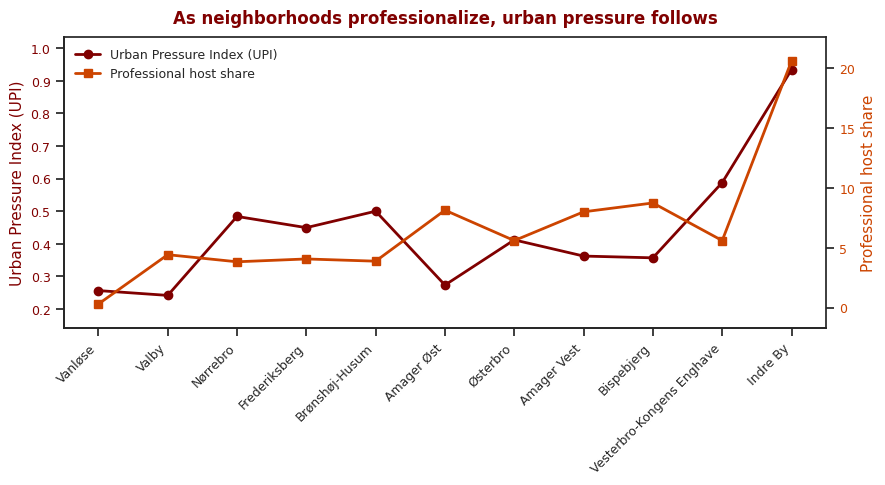

In [85]:
cph_data['rank_upi'] = cph_data['UPI'].rank()
cph_data['rank_ps']  = cph_data['professional_share'].rank()
cph_data['avg_rank'] = (cph_data['rank_upi'] + cph_data['rank_ps']) / 2
cph_sorted = cph_data.sort_values('avg_rank')
neighborhood_names = cph_sorted['neighbourhood'].values
upi_values = cph_sorted['UPI'].values
ps_values = cph_sorted['professional_share'].values

fig, ax1 = plt.subplots(figsize=(9, 5))
sns.despine(ax=ax1, top=True, right=True)


ax1.plot(range(len(neighborhood_names)), upi_values,
         color='#800000', linewidth=2.0, marker='o', markersize=6,
         label='Urban Pressure Index (UPI)')
ax1.set_ylabel('Urban Pressure Index (UPI)', color='#800000', fontsize=11)
ax1.tick_params(axis='y', labelcolor='#800000', labelsize=9)
ax1.set_ylim(upi_values.min() - 0.1, upi_values.max() + 0.1)


ax2 = ax1.twinx()
ax2.plot(range(len(neighborhood_names)), ps_values,
         color='#CC4400', linewidth=2.0, marker='s', markersize=6,
         label='Professional host share')
ax2.set_ylabel('Professional host share', color='#CC4400', fontsize=11)
ax2.tick_params(axis='y', labelcolor='#CC4400', labelsize=9)
ax2.set_ylim(ps_values.min() - 2.0, ps_values.max() + 2.0)


ax1.set_xticks(range(len(neighborhood_names)))
ax1.set_xticklabels(neighborhood_names, rotation=45, ha='right', fontsize=9)


lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2,
           frameon=False, fontsize=9, loc='upper left')

ax1.set_title('As neighborhoods professionalize, urban pressure follows',
              fontsize=12, fontweight='bold', color='#800000', pad=10)

fig.tight_layout()
fig.savefig('data/export/black_hat.png', dpi=dpi, bbox_inches='tight')
print('Saved: black_hat.png')

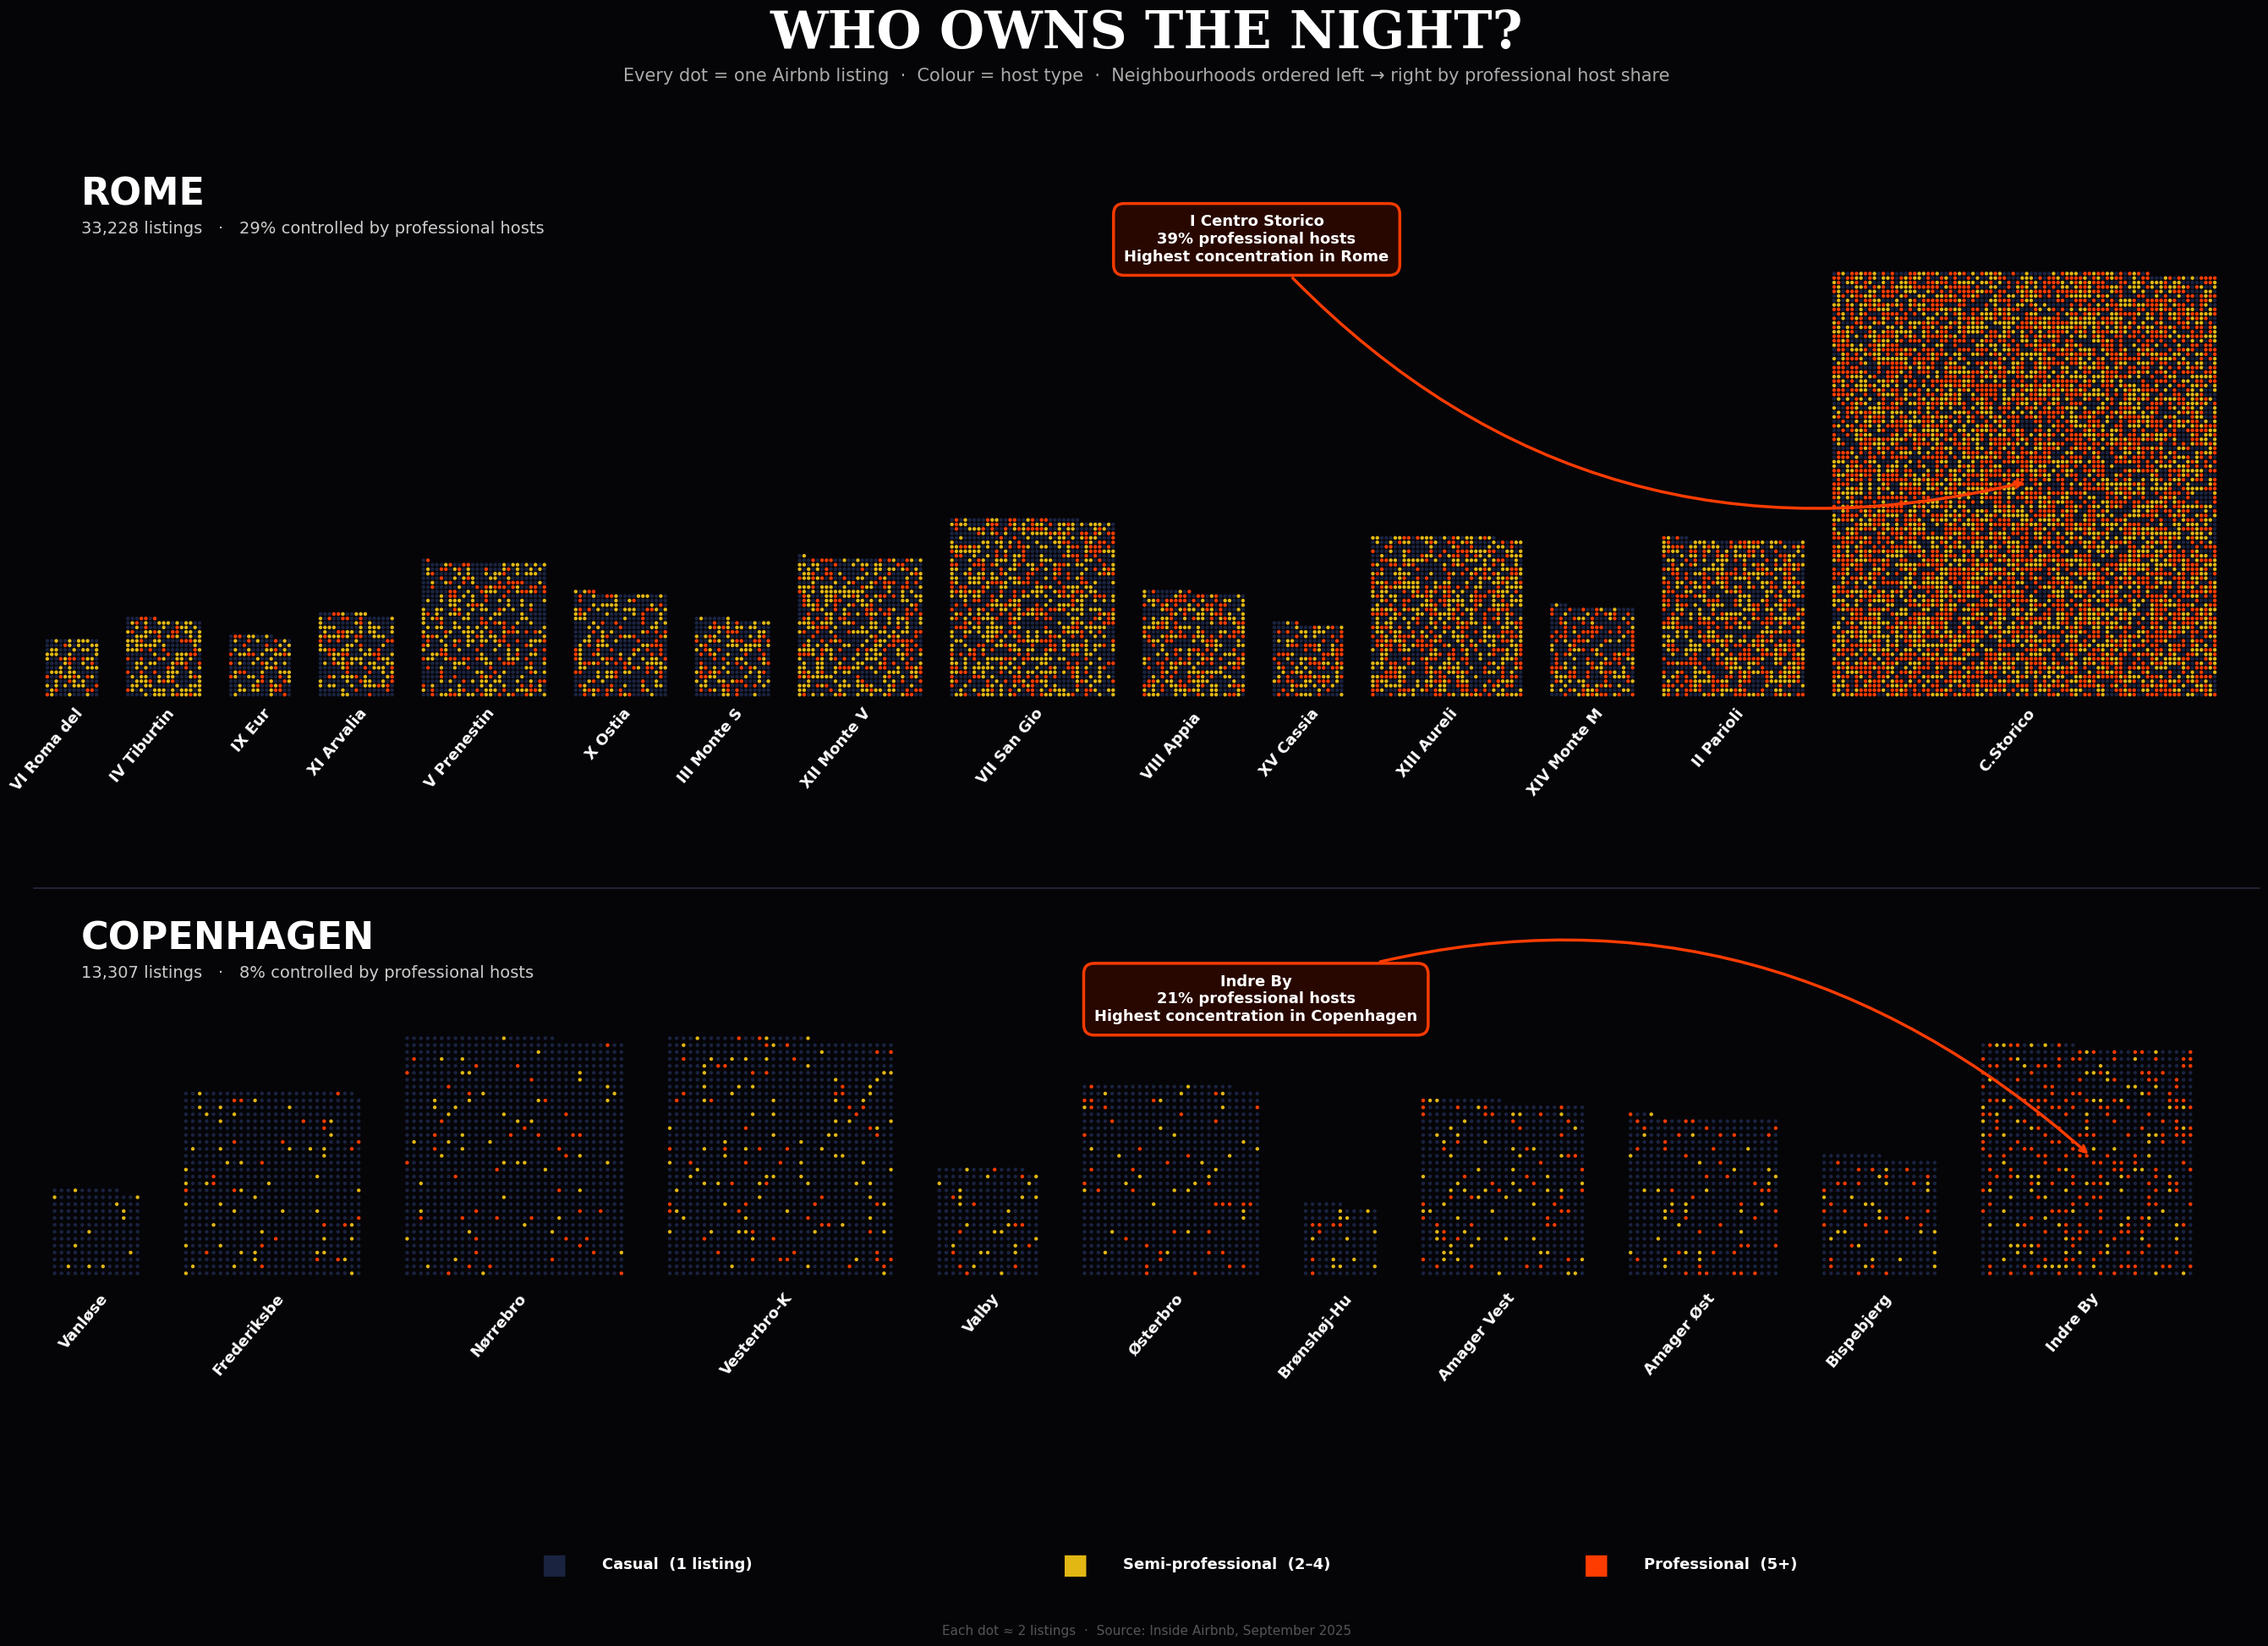

data/export/creative_viz_night.png


In [86]:
df = pd.read_csv('data/export/listings_clean.csv')

COLORS = {
    'Casual':           '#1a2340',
    'Semi-professional':'#e2b714',
    'Professional':     '#ff3c00',
}
BG = '#050508'


def make_grid_by_neighbourhood(data, gap=6):
    pro_pct = {}
    for n, g in data.groupby('neighbourhood'):
        pro_pct[n] = (g['host_category']=='Professional').mean()
    neigh_order = sorted(pro_pct, key=pro_pct.get)
    all_xs, all_ys, all_cs, label_info = [], [], [], []
    current_x = 0
    for neigh in neigh_order:
        group = data[data['neighbourhood']==neigh].copy()
        cats  = list(group['host_category'])
        rng   = np.random.default_rng(hash(neigh) % 2**32)
        rng.shuffle(cats)
        n    = len(cats)
        cols = max(5, int(np.ceil(np.sqrt(n * 0.9))))
        rows = int(np.ceil(n / cols))
        for i, cat in enumerate(cats):
            all_xs.append(current_x + (i % cols))
            all_ys.append(i // cols)
            all_cs.append(COLORS[cat])
        label_info.append((current_x + cols/2, neigh, pro_pct[neigh], cols, rows))
        current_x += cols + gap
    return np.array(all_xs), np.array(all_ys), all_cs, current_x, label_info

def sample_by_neigh(data, scale, seed=42):
    parts = []
    for _, g in data.groupby('neighbourhood'):
        parts.append(g.sample(frac=1/scale, random_state=seed))
    return pd.concat(parts).reset_index(drop=True)

rome   = df[df['city']=='Rome'].copy()
cph    = df[df['city']=='Copenhagen'].copy()
SCALE  = 2
rome_s = sample_by_neigh(rome, SCALE)
cph_s  = sample_by_neigh(cph,  SCALE)

rx, ry, rc, rwidth, r_labels = make_grid_by_neighbourhood(rome_s)
cx, cy, cc, cwidth, c_labels = make_grid_by_neighbourhood(cph_s)

max_ry = int(max(ry))
max_cy = int(max(cy))


fig = plt.figure(figsize=(28, 20), facecolor=BG)


fig.text(0.5, 0.985, 'WHO OWNS THE NIGHT?',
         ha='center', va='top', fontsize=44, fontweight='bold',
         color='white', fontfamily='serif')
fig.text(0.5, 0.950,
         'Every dot = one Airbnb listing  ·  Colour = host type  ·  '
         'Neighbourhoods ordered left → right by professional host share',
         ha='center', va='top', fontsize=15, color='#aaaaaa')


ax1 = fig.add_axes([0.03, 0.50, 0.94, 0.36])
ax1.set_facecolor(BG)
ax1.scatter(rx, ry, c=rc, s=10, linewidths=0, rasterized=True, zorder=2)
ax1.set_aspect('equal')
ax1.axis('off')
ax1.set_xlim(-3, rwidth + 3)
ax1.set_ylim(-22, max_ry + 4)


for (mid_x, neigh, pct, cols, rows) in r_labels:
    short = neigh.replace('I Centro Storico', 'C.Storico')\
                 .replace('Prenestino/Centocelle', 'Prenestino')\
                 .split('/')[0][:11]
    ax1.text(mid_x, -2.5, short,
             ha='right', va='top', fontsize=13, color='white',   # ← CHANGED
             rotation=50, rotation_mode='anchor', fontweight='bold')


fig.text(0.05, 0.875, 'ROME',
         ha='left', va='center', fontsize=32, fontweight='bold', color='white')
n_pro_r   = (rome['host_category']=='Professional').sum()
pct_pro_r = n_pro_r / len(rome) * 100
fig.text(0.05, 0.855,
         f'{len(rome):,} listings   ·   {pct_pro_r:.0f}% controlled by professional hosts',
         ha='left', va='center', fontsize=14, color='#cccccc')


for (mid_x, neigh, pct, cols, rows) in r_labels:
    if 'Centro Storico' in neigh:
        cs_x, cs_pct, cs_rows = mid_x, pct, rows
        break
ax1.annotate(
    f'I Centro Storico\n{cs_pct*100:.0f}% professional hosts\nHighest concentration in Rome',
    xy=(cs_x, cs_rows * 0.5),
    xytext=(rwidth * 0.55, max_ry + 2),
    fontsize=13, color='white', fontweight='bold',
    ha='center', va='bottom',
    bbox=dict(boxstyle='round,pad=0.7', facecolor='#2a0800',
              edgecolor='#ff3c00', linewidth=2.5, alpha=0.97),
    arrowprops=dict(arrowstyle='->', color='#ff3c00',
                    lw=2.5, connectionstyle='arc3,rad=0.3')
)


ax2 = fig.add_axes([0.03, 0.12, 0.94, 0.30])
ax2.set_facecolor(BG)
ax2.scatter(cx, cy, c=cc, s=10, linewidths=0, rasterized=True, zorder=2)
ax2.set_aspect('equal')
ax2.axis('off')
ax2.set_xlim(-3, cwidth + 3)
ax2.set_ylim(-22, max_cy + 4)


for (mid_x, neigh, pct, cols, rows) in c_labels:
    short = neigh[:11]
    ax2.text(mid_x, -2.5, short,
             ha='right', va='top', fontsize=13, color='white',   
             rotation=50, rotation_mode='anchor', fontweight='bold')


fig.text(0.05, 0.435, 'COPENHAGEN',
         ha='left', va='center', fontsize=32, fontweight='bold', color='white')
n_pro_c   = (cph['host_category']=='Professional').sum()
pct_pro_c = n_pro_c / len(cph) * 100
fig.text(0.05, 0.415,
         f'{len(cph):,} listings   ·   {pct_pro_c:.0f}% controlled by professional hosts',
         ha='left', va='center', fontsize=14, color='#cccccc')


for (mid_x, neigh, pct, cols, rows) in c_labels:
    if 'Indre' in neigh:
        ib_x, ib_pct, ib_rows = mid_x, pct, rows
        break
ax2.annotate(
    f'Indre By\n{ib_pct*100:.0f}% professional hosts\nHighest concentration in Copenhagen',
    xy=(ib_x, ib_rows * 0.5),
    xytext=(cwidth * 0.55, max_cy + 2),
    fontsize=13, color='white', fontweight='bold',
    ha='center', va='bottom',
    bbox=dict(boxstyle='round,pad=0.7', facecolor='#2a0800',
              edgecolor='#ff3c00', linewidth=2.5, alpha=0.97),
    arrowprops=dict(arrowstyle='->', color='#ff3c00',
                    lw=2.5, connectionstyle='arc3,rad=-0.3')
)


fig.add_artist(plt.Line2D([0.03, 0.97], [0.465, 0.465],
               color='#222233', linewidth=1.5, transform=fig.transFigure))


items = [
    ('Casual  (1 listing)',      '#1a2340', '#5566aa'),
    ('Semi-professional  (2–4)', '#e2b714', '#e2b714'),
    ('Professional  (5+)',       '#ff3c00', '#ff3c00'),
]
for i, (label, fc, tc) in enumerate(items):
    x = 0.25 + i * 0.22
    fig.text(x,       0.065, '■', fontsize=24, color=fc,
             ha='center', va='center')
    fig.text(x+0.02,  0.065, label, fontsize=13, color='white',
             ha='left', va='center', fontweight='bold')

fig.text(0.5, 0.022,
         f'Each dot ≈ {SCALE} listings  ·  Source: Inside Airbnb, September 2025',
         ha='center', va='bottom', fontsize=11, color='#555555')

plt.savefig('data/export/creative_viz_night.png',
            dpi=180, bbox_inches='tight', facecolor=BG)
plt.show()
print("data/export/creative_viz_night.png")